In [1]:
# STEP 1 — Environment check

import sys
import os
import platform

print("Python:", sys.version)
print("Platform:", platform.platform())

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("GPU available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except Exception as e:
    print("PyTorch check error:", e)

print("\nEnvironment ready.")

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.18.48+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu128
GPU available: True
GPU: Tesla T4

Environment ready.


## 1. Dataset Loading and Initial Inspection

The cricket injury dataset is loaded and inspected before model development.

The inspection verifies:
- Dataset dimensions
- Feature names and data types
- Missing values
- Injury-label distribution
- Potential categorical and numerical variables

No model training or preprocessing decisions are made before understanding the dataset.

In [3]:
import os

print("Kaggle input datasets:\n")

for root, dirs, files in os.walk("/kaggle/input"):
    if files:
        print("FOLDER:", root)
        for file in files:
            print("   FILE:", file)

Kaggle input datasets:

FOLDER: /kaggle/input/datasets/raymondwilfredw/cricket-injury-risk-dataset
   FILE: cricket_player_data_fixed.csv


In [4]:
import pandas as pd

DATA_PATH = "/kaggle/input/datasets/raymondwilfredw/cricket-injury-risk-dataset/cricket_player_data_fixed.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing"))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset loaded successfully.
Shape: (500, 22)

Columns:
['player_id', 'age', 'player_type', 'experience_years', 'height_cm', 'weight_kg', 'bmi', 'body_fat_percent', 'training_hours_week', 'bowling_overs_week', 'batting_hours_week', 'strength_training_hours', 'matches_last_month', 'days_since_last_match', 'previous_injuries_count', 'last_injury_days_ago', 'recovery_days_last_injury', 'fatigue_level', 'sleep_hours_day', 'stress_level', 'fitness_score', 'injury_risk']

First 5 rows:


,player_id,age,player_type,experience_years,height_cm,weight_kg,bmi,body_fat_percent,training_hours_week,bowling_overs_week,...,matches_last_month,days_since_last_match,previous_injuries_count,last_injury_days_ago,recovery_days_last_injury,fatigue_level,sleep_hours_day,stress_level,fitness_score,injury_risk
0,1,24,All-Rounder,9,188.629447,91.612592,25.747567,9.574633,20,22,...,7,18,1,309,75,1,6.939435,9,64,Medium
1,2,37,Bowler,11,179.691932,70.429037,21.811955,20.722534,20,33,...,3,18,1,334,88,5,6.419980,7,81,High
2,3,32,All-Rounder,14,178.618982,68.977879,21.619947,23.547327,17,12,...,4,17,3,175,22,1,6.282849,6,54,Low
3,4,28,All-Rounder,4,187.069279,79.687743,22.771235,15.378357,17,42,...,4,12,0,292,14,7,8.855664,6,61,Medium
4,5,25,All-Rounder,13,185.218583,65.016146,18.951872,12.398098,27,28,...,5,4,4,33,37,1,7.566319,1,45,Low



Data types:


,dtype
player_id,int64
age,int64
player_type,object
experience_years,int64
height_cm,float64
weight_kg,float64
bmi,float64
body_fat_percent,float64
training_hours_week,int64
bowling_overs_week,int64



Missing values:


,missing
player_id,0
age,0
player_type,0
experience_years,0
height_cm,0
weight_kg,0
bmi,0
body_fat_percent,0
training_hours_week,0
bowling_overs_week,0



Duplicate rows: 0


## 2. Injury-Risk Target Analysis

The target variable `injury_risk` is examined before model training.

This step checks:
- Number of Low, Medium and High-risk cases
- Class percentages
- Whether class imbalance is present

The target distribution determines the appropriate evaluation strategy.

In [5]:
# Target distribution

print("Injury-risk counts:")
display(df["injury_risk"].value_counts())

print("\nInjury-risk percentages:")
display(
    (df["injury_risk"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("percentage")
)

print("\nUnique target classes:")
print(df["injury_risk"].unique())

Injury-risk counts:


injury_risk
High      178
Low       174
Medium    148
Name: count, dtype: int64


Injury-risk percentages:


,percentage
injury_risk,
High,35.6
Low,34.8
Medium,29.6



Unique target classes:
['Medium' 'High' 'Low']


In [6]:
# Step 6 — Install and load YOLO Pose

!pip install -q ultralytics

from ultralytics import YOLO
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Pretrained human pose model
pose_model = YOLO("yolo26n-pose.pt")

print("YOLO Pose model loaded successfully.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 2.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu128
GPU available: True
GPU: Tesla T4
YOLO Pose model loaded successfully.


In [7]:
# Step 7 — Download cricket player images

!git clone -q https://github.com/Vignesh-Salian/Cricket-Injury-Predictor.git /kaggle/working/cricket_cv

import os

print("Project downloaded.")

for root, dirs, files in os.walk("/kaggle/working/cricket_cv"):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if image_files:
        print("\nFolder:", root)
        print("Images:", len(image_files))
        print("Examples:", image_files[:5])

Project downloaded.


In [8]:
import os

print("Datasets currently attached to this Kaggle notebook:\n")

for item in os.listdir("/kaggle/input"):
    print("📁", item)

Datasets currently attached to this Kaggle notebook:

📁 datasets


In [9]:
import os

print("All files/folders under /kaggle/input:\n")

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level > 4:
        dirs[:] = []
        continue

    indent = "  " * level

    if files:
        print(f"{indent}{root}")
        for f in files[:10]:
            print(f"{indent}  └── {f}")

All files/folders under /kaggle/input:

      /kaggle/input/datasets/raymondwilfredw/cricket-injury-risk-dataset
        └── cricket_player_data_fixed.csv


In [10]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="jAAWLQP0Wa1cpsPBnPax")
project = rf.workspace("mai-ldivt").project("cricket-r97s2")
version = project.version(1)
dataset = version.download("yolov8")
                

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 4.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 18.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.9 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to cricket-1 in yolov8:: 100%|██████████| 597/597 [00:00<00:00, 7337.45it/s]


In [11]:
DATASET_PATH = "/kaggle/working/cricket-1"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("\nDataset contents:")

for item in os.listdir(DATASET_PATH):
    print(item)

Dataset exists: True

Dataset contents:
data.yaml
README.dataset.txt
README.roboflow.txt
train


In [12]:
import os

TRAIN_PATH = "/kaggle/working/cricket-1/train"

print("Train contents:")

for item in os.listdir(TRAIN_PATH):
    print(item)

Train contents:
images
labels


In [15]:
images_path = "/kaggle/working/cricket-1/train/images"

if os.path.exists(images_path):
    images = os.listdir(images_path)
    print("Number of training images:", len(images))
    print("First 10 images:")
    print(images[:10])
else:
    print("Images folder not found")

Number of training images: 297
First 10 images:
['2022-08-24-114-_png.rf.786f1e623d90fc43947e685d0b12e586.jpg', '2022-08-24-315-_png.rf.a1dd2f291aa4d5150997dfe154a9a044.jpg', '2022-08-24-130-_png.rf.31a57f7992ca65d92408b4a3d8ef520d.jpg', '2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg', '2022-08-24-193-_png.rf.186c60885d6efaebb414198b8156d315.jpg', '2022-08-24-68-_png.rf.07a9b6cb77204a0551a4e91fa0a007da.jpg', '2022-08-24-173-_png.rf.965220f75f0f51dc3c991be32eafd6ad.jpg', '2022-08-24-133-_png.rf.ce3fa7b1b3152b7803c01a11ed7c350f.jpg', '2022-08-24-301-_png.rf.f3405b810cbba573f42c8f48793f180f.jpg', '2022-08-24-35-_png.rf.53e1dadc414092878bc0bbf2c6d36621.jpg']


In [16]:
# STEP 10 — Run YOLO26-Pose on cricket images

import os
from ultralytics import YOLO

IMAGE_PATH = "/kaggle/working/cricket-1/train/images"
POSE_OUTPUT = "/kaggle/working/pose_results"

os.makedirs(POSE_OUTPUT, exist_ok=True)

results = pose_model.predict(
    source=IMAGE_PATH,
    save=True,
    save_txt=True,
    project=POSE_OUTPUT,
    name="cricket_pose",
    conf=0.25,
    device=0
)

print("Pose estimation completed.")
print("Output:", os.path.join(POSE_OUTPUT, "cricket_pose"))


image 1/297 /kaggle/working/cricket-1/train/images/2022-08-24-10-_png.rf.28ba3896dc17e38f524e02f1e7f4c163.jpg: 384x640 5 persons, 10.8ms
image 2/297 /kaggle/working/cricket-1/train/images/2022-08-24-100-_png.rf.f94ebc061648d2e614b905e588c75d79.jpg: 384x640 (no detections), 14.8ms
image 3/297 /kaggle/working/cricket-1/train/images/2022-08-24-101-_png.rf.eaf5fed20c51a2544dc5f01bfc2a0c4a.jpg: 384x640 4 persons, 13.7ms
image 4/297 /kaggle/working/cricket-1/train/images/2022-08-24-102-_png.rf.9574c1cb854537dbb5d20b61adfc9f01.jpg: 384x640 5 persons, 10.6ms
image 5/297 /kaggle/working/cricket-1/train/images/2022-08-24-104-_png.rf.1023a8cc3a6443b91a22059e803e03bd.jpg: 384x640 3 persons, 15.7ms
image 6/297 /kaggle/working/cricket-1/train/images/2022-08-24-105-_png.rf.96fc08ffea127584e3c07c42bca84d4c.jpg: 384x640 3 persons, 14.2ms
image 7/297 /kaggle/working/cricket-1/train/images/2022-08-24-106-_png.rf.fc092ecc63b24f12ce299ddabcb47073.jpg: 384x640 5 persons, 13.8ms
image 8/297 /kaggle/working/

In [18]:
# Check exactly what paths Roboflow put in data.yaml

print(open("/kaggle/working/cricket-1/data.yaml").read())

names:
- Ball
- Batsmen
- Bowler
- Fielder
- Umpire
- Wicket
- Wicket-Keeper
nc: 7
roboflow:
  license: CC BY 4.0
  project: cricket-r97s2
  url: https://universe.roboflow.com/mai-ldivt/cricket-r97s2/dataset/1
  version: 1
  workspace: mai-ldivt
test: ../test/images
train: ../train/images
val: ../valid/images



In [20]:
# FIX: Create train / valid / test splits safely

import shutil
import random
from pathlib import Path

BASE = Path("/kaggle/working/cricket-1")

SOURCE_IMAGES = BASE / "train" / "images"
SOURCE_LABELS = BASE / "train" / "labels"

# Get the original 297 images
images = list(SOURCE_IMAGES.glob("*.jpg")) + \
         list(SOURCE_IMAGES.glob("*.jpeg")) + \
         list(SOURCE_IMAGES.glob("*.png"))

random.seed(42)
random.shuffle(images)

# Split
n = len(images)

n_train = int(0.70 * n)
n_val = int(0.20 * n)

train_images = images[:n_train]
val_images = images[n_train:n_train + n_val]
test_images = images[n_train + n_val:]

print("Total:", len(images))
print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))

# Create only valid/test folders
# DO NOT recreate train because original train is already there
for split in ["valid", "test"]:
    split_dir = BASE / split

    if split_dir.exists():
        shutil.rmtree(split_dir)

    (split_dir / "images").mkdir(parents=True, exist_ok=True)
    (split_dir / "labels").mkdir(parents=True, exist_ok=True)


def copy_split(image_list, split):
    for img in image_list:

        # Copy image
        destination_image = BASE / split / "images" / img.name
        shutil.copy2(img, destination_image)

        # Copy matching YOLO label
        label = SOURCE_LABELS / (img.stem + ".txt")

        if label.exists():
            destination_label = BASE / split / "labels" / label.name
            shutil.copy2(label, destination_label)


# Only create validation and test
copy_split(val_images, "valid")
copy_split(test_images, "test")

print("\nDataset split completed successfully.")

Total: 297
Train: 207
Validation: 59
Test: 31

Dataset split completed successfully.


In [21]:
from pathlib import Path

BASE = Path("/kaggle/working/cricket-1")

for split in ["train", "valid", "test"]:
    images = list((BASE / split / "images").glob("*"))
    labels = list((BASE / split / "labels").glob("*.txt"))

    print(f"{split}:")
    print("  images:", len(images))
    print("  labels:", len(labels))

train:
  images: 297
  labels: 297
valid:
  images: 59
  labels: 59
test:
  images: 31
  labels: 31


In [22]:
from pathlib import Path

BASE = Path("/kaggle/working/cricket-1")

train_images_dir = BASE / "train" / "images"
train_labels_dir = BASE / "train" / "labels"

valid_images_dir = BASE / "valid" / "images"
test_images_dir = BASE / "test" / "images"

# Get validation and test filenames
valid_names = {p.name for p in valid_images_dir.iterdir() if p.is_file()}
test_names = {p.name for p in test_images_dir.iterdir() if p.is_file()}

# Remove validation/test images from training
removed_images = 0
removed_labels = 0

for image_name in valid_names | test_names:

    image_path = train_images_dir / image_name

    if image_path.exists():
        image_path.unlink()
        removed_images += 1

    # Corresponding YOLO label
    label_path = train_labels_dir / (Path(image_name).stem + ".txt")

    if label_path.exists():
        label_path.unlink()
        removed_labels += 1

print("Removed from original train folder:")
print("Images:", removed_images)
print("Labels:", removed_labels)

# Final count
print("\nFinal dataset:")
print("Train images:", len(list(train_images_dir.glob("*"))))
print("Valid images:", len(list(valid_images_dir.glob("*"))))
print("Test images:", len(list(test_images_dir.glob("*"))))

Removed from original train folder:
Images: 90
Labels: 90

Final dataset:
Train images: 207
Valid images: 59
Test images: 31


In [23]:
from pathlib import Path

yaml_path = Path("/kaggle/working/cricket-1/data.yaml")

yaml_content = """path: /kaggle/working/cricket-1

train: train/images
val: valid/images
test: test/images

nc: 7

names:
- Ball
- Batsmen
- Bowler
- Fielder
- Umpire
- Wicket
- Wicket-Keeper
"""

yaml_path.write_text(yaml_content)

print("data.yaml updated successfully.\n")
print(yaml_path.read_text())

data.yaml updated successfully.

path: /kaggle/working/cricket-1

train: train/images
val: valid/images
test: test/images

nc: 7

names:
- Ball
- Batsmen
- Bowler
- Fielder
- Umpire
- Wicket
- Wicket-Keeper



In [24]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(
    data="/kaggle/working/cricket-1/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="/kaggle/working/runs",
    name="cricket_yolo_50epochs"
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/cricket-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cricket_yolo_50epochs-2, nbs=64, nms=None, opset=None

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      2.66G       1.09      4.336   0.003599        127        640: 100% ━━━━━━━━━━━━ 13/13 6.5it/s 2.0s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 6.3it/s 0.3s0.6s
                   all         59        324     0.0135      0.589      0.144     0.0949

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      2.66G      1.195       3.94   0.003755        167        640: 100% ━━━━━━━━━━━━ 13/13 6.6it/s 2.0s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 6.4it/s 0.3s0.5s
                   all         59        324     0.0114      0.592      0.168      0.111

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      2.66G      1.152       3.52   0.003807        166        640: 100% ━━━━━━━━━━━━ 13/13 6.9it/s 1.9s0.2s
                 Class     Images  Instances  

In [25]:
from ultralytics import YOLO
from pathlib import Path

# Load your trained 50-epoch model
model = YOLO(
    "/kaggle/working/runs/cricket_yolo_50epochs-2/weights/best.pt"
)

# Pick one test image
test_images = list(
    Path("/kaggle/working/cricket-1/test/images").glob("*.jpg")
)

image_path = str(test_images[0])

print("Testing image:")
print(image_path)

# Detect and draw boxes + class names
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True,
    project="/kaggle/working/predictions",
    name="test_prediction"
)

print("\nPrediction completed.")
print("Output folder:")
print("/kaggle/working/predictions/test_prediction")

Testing image:
/kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg

image 1/1 /kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg: 384x640 2 Batsmens, 1 Bowler, 2 Fielders, 1 Umpire, 2 Wickets, 1 Wicket-Keeper, 9.0ms
Speed: 1.8ms preprocess, 9.0ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /kaggle/working/predictions/test_prediction

Prediction completed.
Output folder:
/kaggle/working/predictions/test_prediction


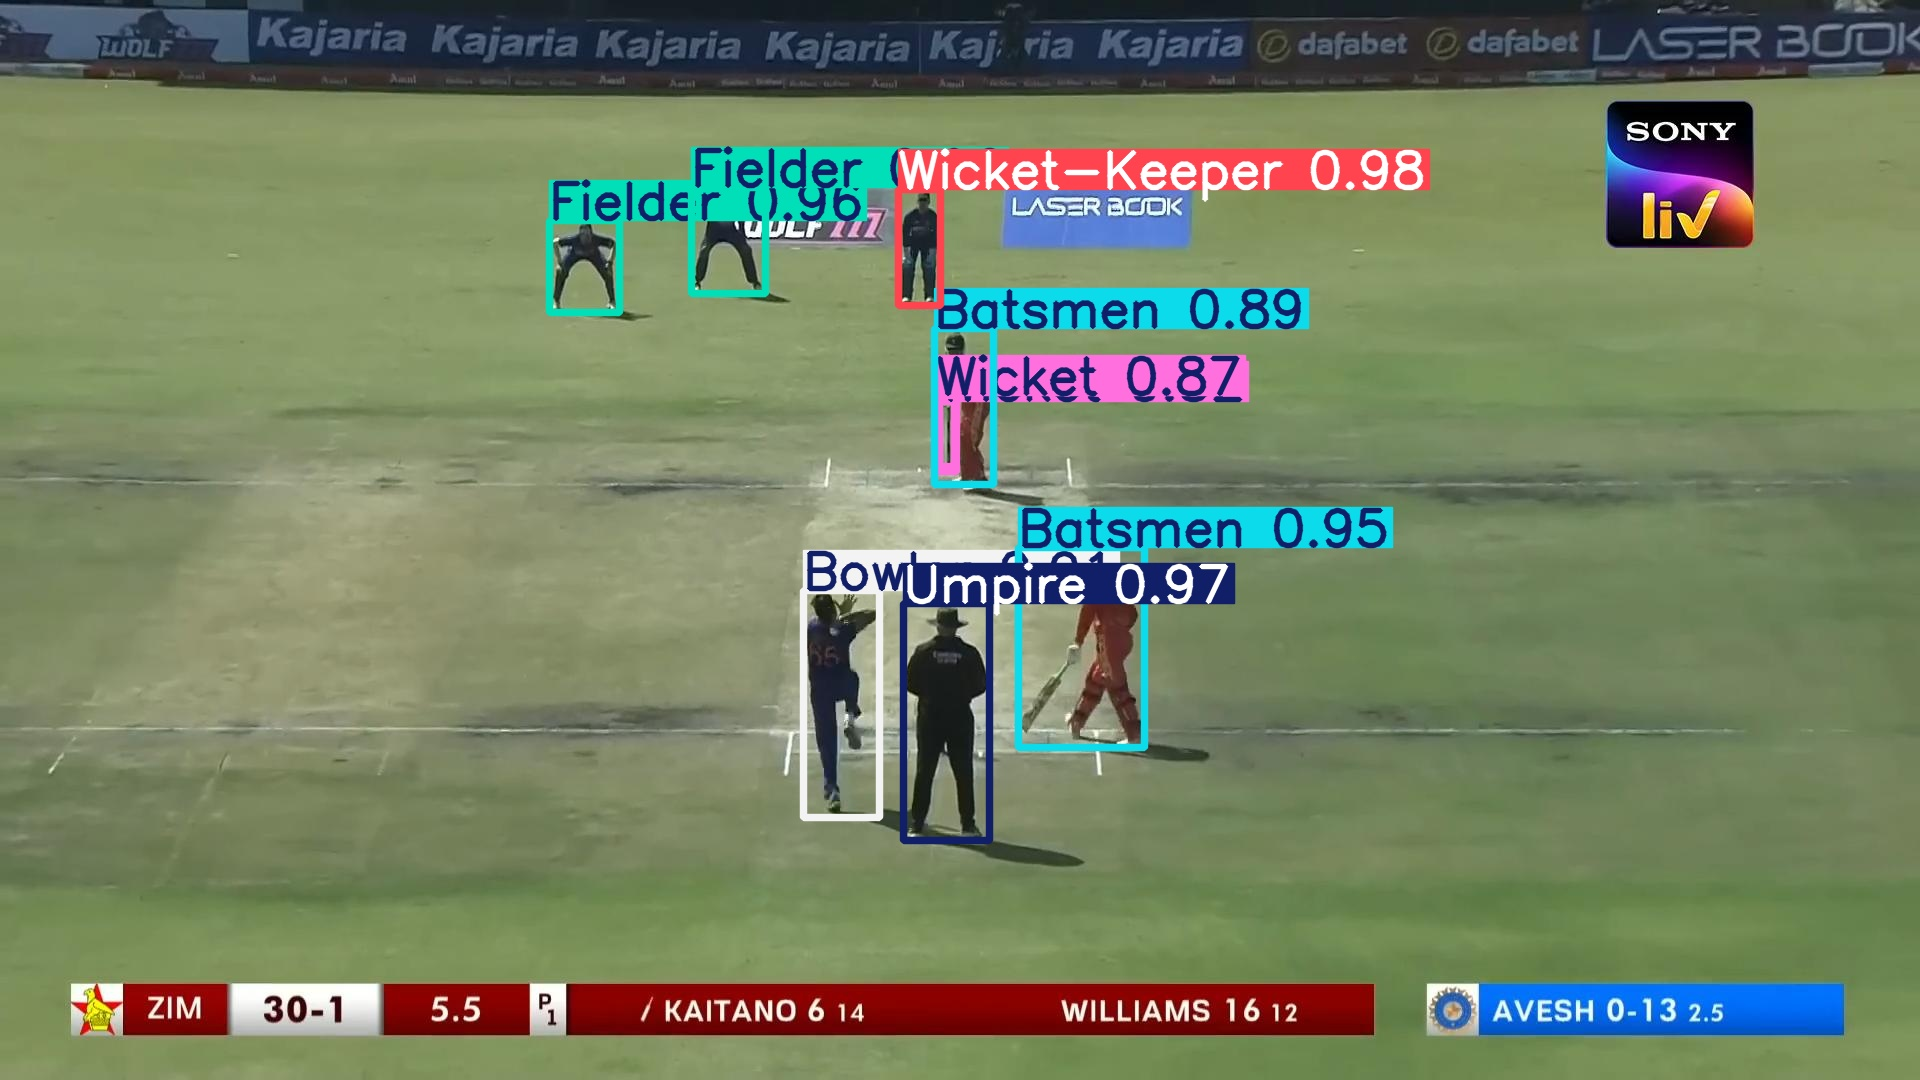

In [26]:
from IPython.display import Image, display
from pathlib import Path

output_dir = Path("/kaggle/working/predictions/test_prediction")

predicted_image = list(output_dir.glob("*.jpg"))[0]

display(Image(filename=str(predicted_image)))

In [27]:
from ultralytics import YOLO

# Load pose model
pose_model = YOLO("yolo26n-pose.pt")

# Same test image
image_path = "/kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg"

# Pose estimation
pose_results = pose_model.predict(
    source=image_path,
    conf=0.25,
    save=True,
    project="/kaggle/working/pose_predictions",
    name="bowler_pose",
    device=0
)

print("Pose estimation completed.")
print("Output:")
print("/kaggle/working/pose_predictions/bowler_pose")


image 1/1 /kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg: 384x640 3 persons, 9.5ms
Speed: 1.6ms preprocess, 9.5ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /kaggle/working/pose_predictions/bowler_pose
Pose estimation completed.
Output:
/kaggle/working/pose_predictions/bowler_pose


In [28]:
# Get pose keypoints from the prediction

result = pose_results[0]

if result.keypoints is not None:
    keypoints = result.keypoints.xy.cpu().numpy()

    print("Number of persons:", len(keypoints))
    print("Keypoints shape:", keypoints.shape)
    print("\nFirst person's 17 keypoints:")
    print(keypoints[0])
else:
    print("No pose keypoints detected.")

Number of persons: 3
Keypoints shape: (3, 17, 2)

First person's 17 keypoints:
[[     952.38       626.6]
 [     950.57      622.19]
 [     952.62      622.22]
 [     938.29      624.54]
 [     959.33      625.14]
 [     924.63      650.15]
 [     970.27      653.05]
 [     911.87      679.21]
 [     981.24      684.94]
 [     924.41      688.93]
 [     964.47      697.06]
 [     929.84      716.64]
 [     960.54      717.84]
 [     924.51       767.8]
 [     963.66      769.28]
 [     918.61      818.72]
 [     967.66       820.7]]


In [30]:
import numpy as np

def calculate_angle(a, b, c):
    """
    Angle ABC:
    a = first point
    b = middle point
    c = third point
    """
    a = np.array(a)
    b = np.array(b)
    c = np.array(c)

    ba = a - b
    bc = c - b

    cosine_angle = np.dot(ba, bc) / (
        np.linalg.norm(ba) * np.linalg.norm(bc)
    )

    cosine_angle = np.clip(cosine_angle, -1.0, 1.0)

    angle = np.degrees(np.arccos(cosine_angle))

    return angle


# First detected person's keypoints
person = keypoints[0]

# Left knee
left_hip = person[11]
left_knee = person[13]
left_ankle = person[15]

# Right knee
right_hip = person[12]
right_knee = person[14]
right_ankle = person[16]

left_knee_angle = calculate_angle(
    left_hip,
    left_knee,
    left_ankle
)

right_knee_angle = calculate_angle(
    right_hip,
    right_knee,
    right_ankle
)

print("Left Knee Angle :", round(left_knee_angle, 2), "degrees")
print("Right Knee Angle:", round(right_knee_angle, 2), "degrees")

Left Knee Angle : 179.33 degrees
Right Knee Angle: 179.01 degrees


In [34]:
from ultralytics import YOLO
from IPython.display import Image, display
from pathlib import Path

# Load your trained 50-epoch cricket detector
detector = YOLO(
    "/kaggle/working/runs/cricket_yolo_50epochs-2/weights/best.pt"
)

image_path = "/kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg"

# Run object detection
results = detector.predict(
    source=image_path,
    conf=0.15,
    imgsz=1280,
    device=0
)

result = results[0]

# Class names
names = detector.names

print("Detected objects:")

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    class_name = names[class_id]

    print(
        f"{class_name}: {confidence:.2f}"
    )


image 1/1 /kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg: 736x1280 2 Batsmens, 2 Bowlers, 2 Fielders, 2 Umpires, 1 Wicket, 1 Wicket-Keeper, 13.0ms
Speed: 4.6ms preprocess, 13.0ms inference, 1.2ms postprocess per image at shape (1, 3, 736, 1280)
Detected objects:
Umpire: 0.99
Fielder: 0.94
Fielder: 0.94
Batsmen: 0.91
Batsmen: 0.89
Wicket-Keeper: 0.78
Wicket: 0.76
Bowler: 0.67
Bowler: 0.24
Umpire: 0.18


Saved image:
/kaggle/working/wicketkeeper_detection.jpg


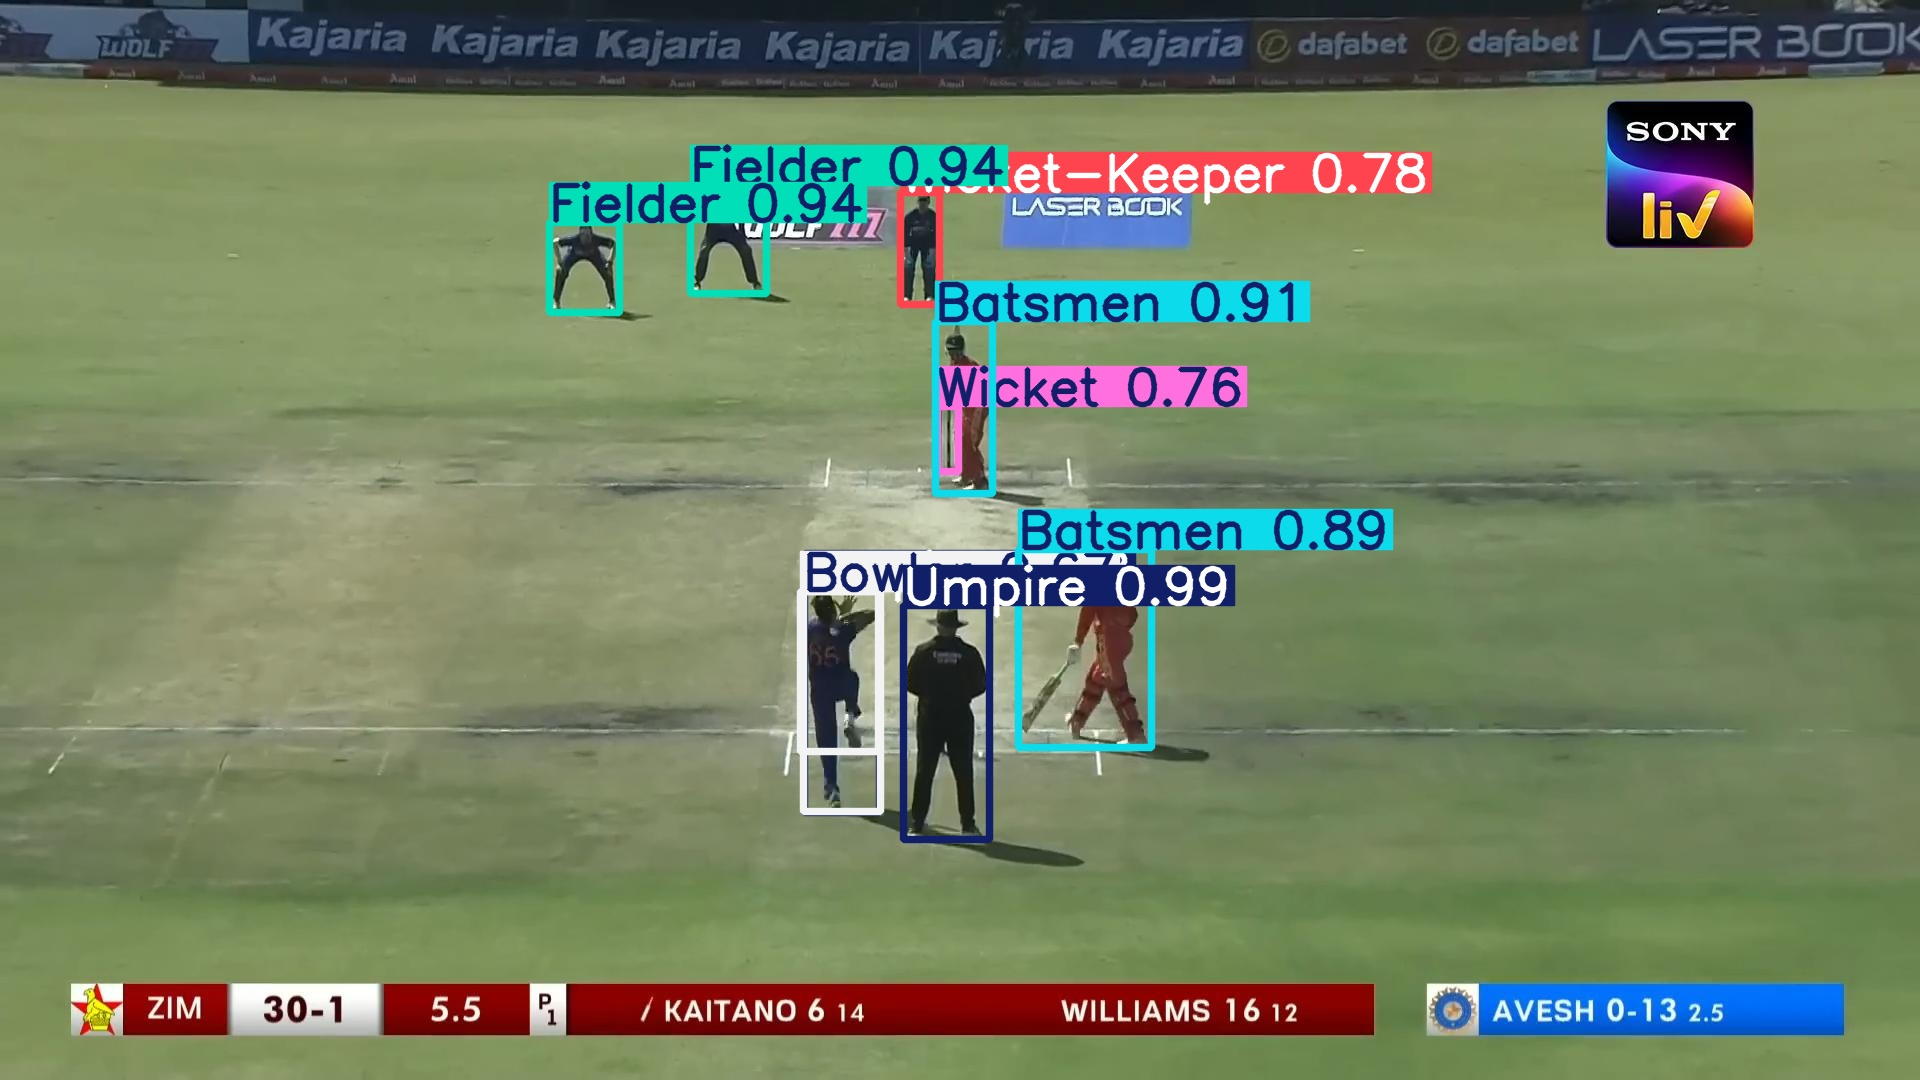

In [35]:
from IPython.display import display
from PIL import Image
import cv2

# Get the annotated image from YOLO
annotated_image = results[0].plot()

# Save it
output_path = "/kaggle/working/wicketkeeper_detection.jpg"
cv2.imwrite(output_path, annotated_image)

print("Saved image:")
print(output_path)

# Display inside Kaggle
display(Image.open(output_path))


image 1/1 /kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg: 736x1280 2 Batsmens, 2 Bowlers, 2 Fielders, 2 Umpires, 1 Wicket, 1 Wicket-Keeper, 13.0ms
Speed: 4.6ms preprocess, 13.0ms inference, 1.2ms postprocess per image at shape (1, 3, 736, 1280)
Wicket-Keeper confidence: 0.778
Bounding box: [     900.66      192.54      939.76      304.92]
Wicket-keeper crop saved:
/kaggle/working/wicket_keeper_crop.jpg

image 1/1 /kaggle/working/wicket_keeper_crop.jpg: 1280x960 3 persons, 21.0ms
Speed: 5.9ms preprocess, 21.0ms inference, 1.3ms postprocess per image at shape (1, 3, 1280, 960)


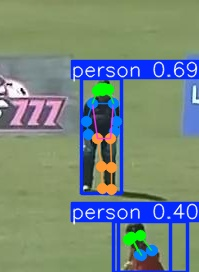

Wicket-keeper pose image:
/kaggle/working/wicket_keeper_pose.jpg
Persons detected in wicket-keeper crop: 3


In [37]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import cv2

# Load trained cricket detector
detector = YOLO(
    "/kaggle/working/runs/cricket_yolo_50epochs-2/weights/best.pt"
)

# Load pose model
pose_model = YOLO("yolo26n-pose.pt")

image_path = "/kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg"

# --------------------------------------------------
# 1. Detect wicket-keeper
# --------------------------------------------------

det_results = detector.predict(
    source=image_path,
    conf=0.15,
    imgsz=1280,
    device=0
)

result = det_results[0]

wicket_keeper_box = None

for box in result.boxes:
    class_id = int(box.cls[0])
    class_name = detector.names[class_id]
    confidence = float(box.conf[0])

    if class_name == "Wicket-Keeper":
        wicket_keeper_box = box.xyxy[0].cpu().numpy()
        print("Wicket-Keeper confidence:", round(confidence, 3))
        print("Bounding box:", wicket_keeper_box)
        break

if wicket_keeper_box is None:
    print("Wicket-Keeper not detected.")
else:

    # --------------------------------------------------
    # 2. Crop wicket-keeper
    # --------------------------------------------------

    image = cv2.imread(image_path)

    x1, y1, x2, y2 = map(int, wicket_keeper_box)

    # Add padding around the wicket-keeper
    padding = 80

    x1 = max(0, x1 - padding)
    y1 = max(0, y1 - padding)
    x2 = min(image.shape[1], x2 + padding)
    y2 = min(image.shape[0], y2 + padding)

    keeper_crop = image[y1:y2, x1:x2]

    crop_path = "/kaggle/working/wicket_keeper_crop.jpg"

    cv2.imwrite(crop_path, keeper_crop)

    print("Wicket-keeper crop saved:")
    print(crop_path)

    # --------------------------------------------------
    # 3. Run pose only on wicket-keeper crop
    # --------------------------------------------------

    pose_results = pose_model.predict(
        source=crop_path,
        conf=0.10,
        imgsz=1280,
        device=0
    )

    # --------------------------------------------------
    # 4. Display pose image
    # --------------------------------------------------

    pose_image = pose_results[0].plot()

    pose_output = "/kaggle/working/wicket_keeper_pose.jpg"

    cv2.imwrite(pose_output, pose_image)

    display(Image.open(pose_output))

    print("Wicket-keeper pose image:")
    print(pose_output)

    if pose_results[0].keypoints is not None:
        print(
            "Persons detected in wicket-keeper crop:",
            len(pose_results[0].keypoints.xy)
        )


image 1/1 /kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg: 864x1536 7 persons, 23.0ms
Speed: 6.1ms preprocess, 23.0ms inference, 1.3ms postprocess per image at shape (1, 3, 864, 1536)


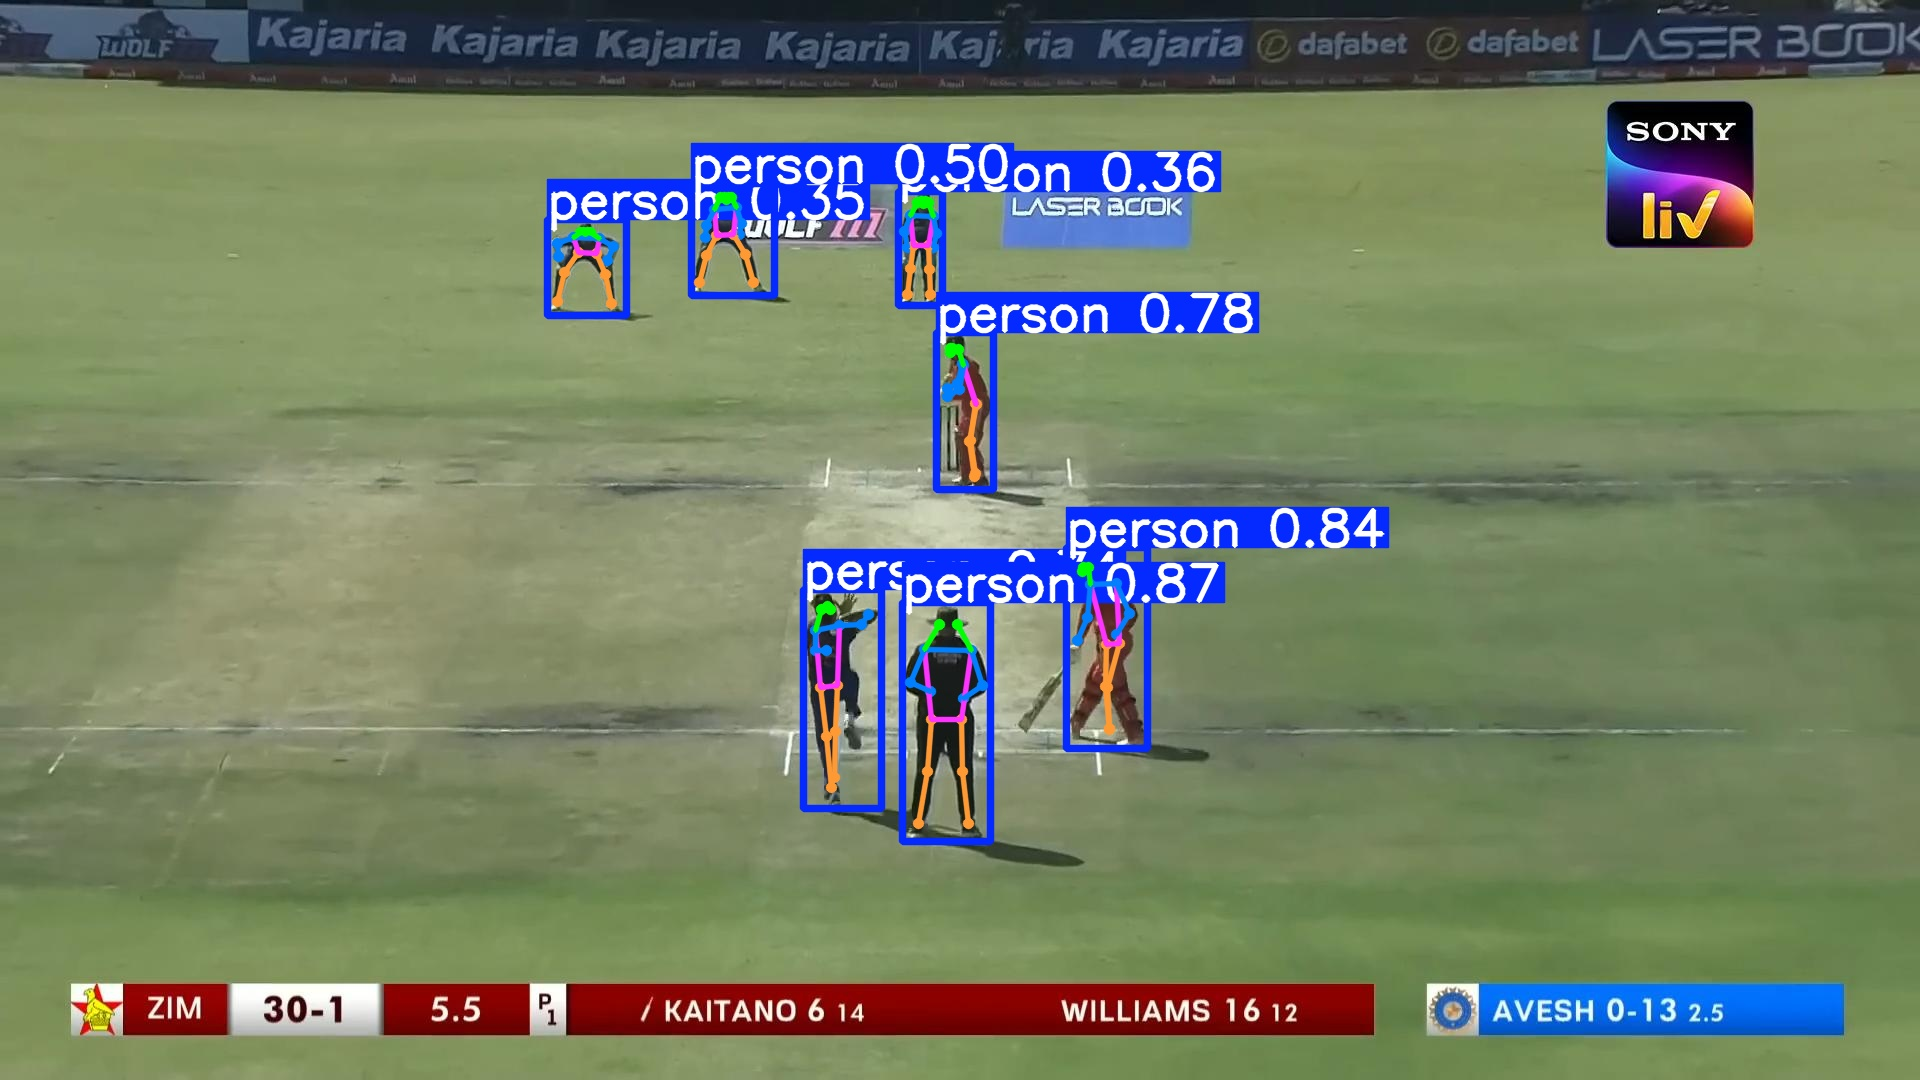

Persons with pose:
7


In [39]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import cv2

pose_model = YOLO("yolo26n-pose.pt")

image_path = "/kaggle/working/cricket-1/test/images/2022-08-24-198-_png.rf.b0ae3793e443292c127adacd7865b3a6.jpg"

results = pose_model.predict(
    source=image_path,
    conf=0.05,
    imgsz=1536,
    device=0,
    save=False
)

# Full image + pose keypoints
annotated = results[0].plot()

output_path = "/kaggle/working/full_cricket_pose_1536.jpg"
cv2.imwrite(output_path, annotated)

display(Image.open(output_path))

print("Persons with pose:")
print(len(results[0].keypoints.xy))

## 🧬 Biomechanical Feature Extraction

The pose-estimation output provides 17 body keypoints for each detected player.

These keypoints are converted into geometric biomechanical features:

- Left knee angle
- Right knee angle
- Trunk angle
- Shoulder angle
- Hip angle
- Shoulder-hip rotation

These features represent movement geometry extracted from the video/image and are used as inputs for subsequent injury-risk analysis.

The measurements are not medical diagnoses.

## 🧬 Biomechanical Feature Extraction

The pose-estimation output provides 17 body keypoints for each detected player.

These keypoints are converted into geometric biomechanical features:

- Left knee angle
- Right knee angle
- Trunk angle
- Shoulder angle
- Hip angle
- Shoulder-hip rotation

These features represent movement geometry extracted from the video/image and are used as inputs for subsequent injury-risk analysis.

The measurements are not medical diagnoses.

## 🧍 YOLO26n Pose Estimation

In [5]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 5.1 MB/s eta 0:00:00


## 📂 Locate Test Image

In [7]:
import os

test_folder = "/kaggle/working/cricket-1/test/images"

print("Folder exists:", os.path.exists(test_folder))

if os.path.exists(test_folder):
    images = [
        f for f in os.listdir(test_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Number of test images:", len(images))
    print("\nTest images:")
    for i, image in enumerate(images):
        print(i, image)
else:
    print("Test folder does not exist.")

Folder exists: False
Test folder does not exist.


## 📦 Download Cricket Dataset

The Roboflow cricket dataset is downloaded again after the Kaggle session reset.

In [9]:
!pip install -q roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 105.9 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.9 MB/s eta 0:00:00


In [11]:
from roboflow import Roboflow

rf = Roboflow(api_key="jAAWLQP0Wa1cpsPBnPax")

project = rf.workspace("mai-ldivt").project("cricket-r97s2")
dataset = project.version(1).download("yolov8")

print("Dataset downloaded to:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to cricket-1 in yolov8:: 100%|██████████| 597/597 [00:00<00:00, 7300.14it/s]


Dataset downloaded to: /kaggle/working/cricket-1


## 📊 Cricket Dataset Split

The Roboflow cricket dataset is divided into training, validation, and test sets.

In [12]:
import os
import random
import shutil

BASE = "/kaggle/working/cricket-1"
SOURCE_IMAGES = os.path.join(BASE, "train", "images")
SOURCE_LABELS = os.path.join(BASE, "train", "labels")

VALID_IMAGES = os.path.join(BASE, "valid", "images")
VALID_LABELS = os.path.join(BASE, "valid", "labels")

TEST_IMAGES = os.path.join(BASE, "test", "images")
TEST_LABELS = os.path.join(BASE, "test", "labels")

os.makedirs(VALID_IMAGES, exist_ok=True)
os.makedirs(VALID_LABELS, exist_ok=True)
os.makedirs(TEST_IMAGES, exist_ok=True)
os.makedirs(TEST_LABELS, exist_ok=True)

images = [
    f for f in os.listdir(SOURCE_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

random.seed(42)
random.shuffle(images)

total = len(images)

train_count = int(total * 0.70)
valid_count = int(total * 0.20)

valid_images = images[train_count:train_count + valid_count]
test_images = images[train_count + valid_count:]

print("Total images:", total)
print("Train images:", train_count)
print("Validation images:", len(valid_images))
print("Test images:", len(test_images))

def move_pair(filename, destination_images, destination_labels):
    image_src = os.path.join(SOURCE_IMAGES, filename)

    label_name = os.path.splitext(filename)[0] + ".txt"
    label_src = os.path.join(SOURCE_LABELS, label_name)

    shutil.move(image_src, os.path.join(destination_images, filename))

    if os.path.exists(label_src):
        shutil.move(label_src, os.path.join(destination_labels, label_name))

for filename in valid_images:
    move_pair(filename, VALID_IMAGES, VALID_LABELS)

for filename in test_images:
    move_pair(filename, TEST_IMAGES, TEST_LABELS)

print("\nSplit completed.")

Total images: 297
Train images: 207
Validation images: 59
Test images: 31

Split completed.


In [13]:
print("Train:", len(os.listdir(SOURCE_IMAGES)))
print("Valid:", len(os.listdir(VALID_IMAGES)))
print("Test:", len(os.listdir(TEST_IMAGES)))

Train: 207
Valid: 59
Test: 31


## ⚙️ YOLO Dataset Configuration

Configure the training, validation, and test paths for the cricket object-detection dataset.

In [14]:
yaml_content = """
path: /kaggle/working/cricket-1

train: train/images
val: valid/images
test: test/images

nc: 7

names:
- Ball
- Batsmen
- Bowler
- Fielder
- Umpire
- Wicket
- Wicket-Keeper
"""

with open("/kaggle/working/cricket-1/data.yaml", "w") as f:
    f.write(yaml_content)

print("data.yaml created successfully.")

data.yaml created successfully.


In [15]:
with open("/kaggle/working/cricket-1/data.yaml", "r") as f:
    print(f.read())


path: /kaggle/working/cricket-1

train: train/images
val: valid/images
test: test/images

nc: 7

names:
- Ball
- Batsmen
- Bowler
- Fielder
- Umpire
- Wicket
- Wicket-Keeper



## 🏏 YOLO26n Cricket Object Detection — 50 Epochs

Train the YOLO26n model on the cricket dataset for 50 epochs.

In [16]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

results = model.train(
    data="/kaggle/working/cricket-1/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="/kaggle/working/runs",
    name="cricket_yolo_50epochs"
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/cricket-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cricket_yolo_50epochs, nbs=64, nms=None, opset=None, 

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      2.68G      1.129      4.424    0.00362        134        640: 100% ━━━━━━━━━━━━ 13/13 6.6it/s 2.0s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 6.5it/s 0.3s0.5s
                   all         59        334     0.0131      0.552       0.12     0.0857

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      2.68G      1.159       3.95   0.003867        156        640: 100% ━━━━━━━━━━━━ 13/13 6.8it/s 1.9s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 5.9it/s 0.3s0.6s
                   all         59        334     0.0106      0.501      0.144      0.107

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      2.68G      1.169      3.444    0.00396        156        640: 100% ━━━━━━━━━━━━ 13/13 6.6it/s 2.0s0.2s
                 Class     Images  Instances  

## 🧪 Final Test Evaluation

Evaluate the trained YOLO26n model on the unseen test set.

In [17]:
from ultralytics import YOLO

best_model = YOLO(
    "/kaggle/working/runs/cricket_yolo_50epochs/weights/best.pt"
)

test_results = best_model.val(
    data="/kaggle/working/cricket-1/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 120 layers, 2,376,201 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2592.4±773.0 MB/s, size: 119.1 KB)
val: Scanning /kaggle/working/cricket-1/test/labels... 31 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 31/31 1.3Kit/s 0.0s
val: New cache created: /kaggle/working/cricket-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.8it/s 1.1s1.8s
                   all         31        158      0.853      0.733      0.797      0.642
                  Ball         21         21      0.856      0.283      0.417      0.201
               Batsmen         22         40      0.869       0.95       0.94      0.878
                Bowler         18         18      0.939      0.849       0.94      0.751
               Fielder         17         21      0.758      0.90

## 🧍 Player Pose Estimation

YOLO26n-Pose is used to detect human body keypoints from cricket images.

The model provides 17 COCO body keypoints for each detected player.

Using image:
/kaggle/working/cricket-1/test/images/2022-08-24-196-_png.rf.4e51f5021d6ab7d514433019d94a7d07.jpg

image 1/1 /kaggle/working/cricket-1/test/images/2022-08-24-196-_png.rf.4e51f5021d6ab7d514433019d94a7d07.jpg: 864x1536 6 persons, 23.0ms
Speed: 8.5ms preprocess, 23.0ms inference, 1.5ms postprocess per image at shape (1, 3, 864, 1536)


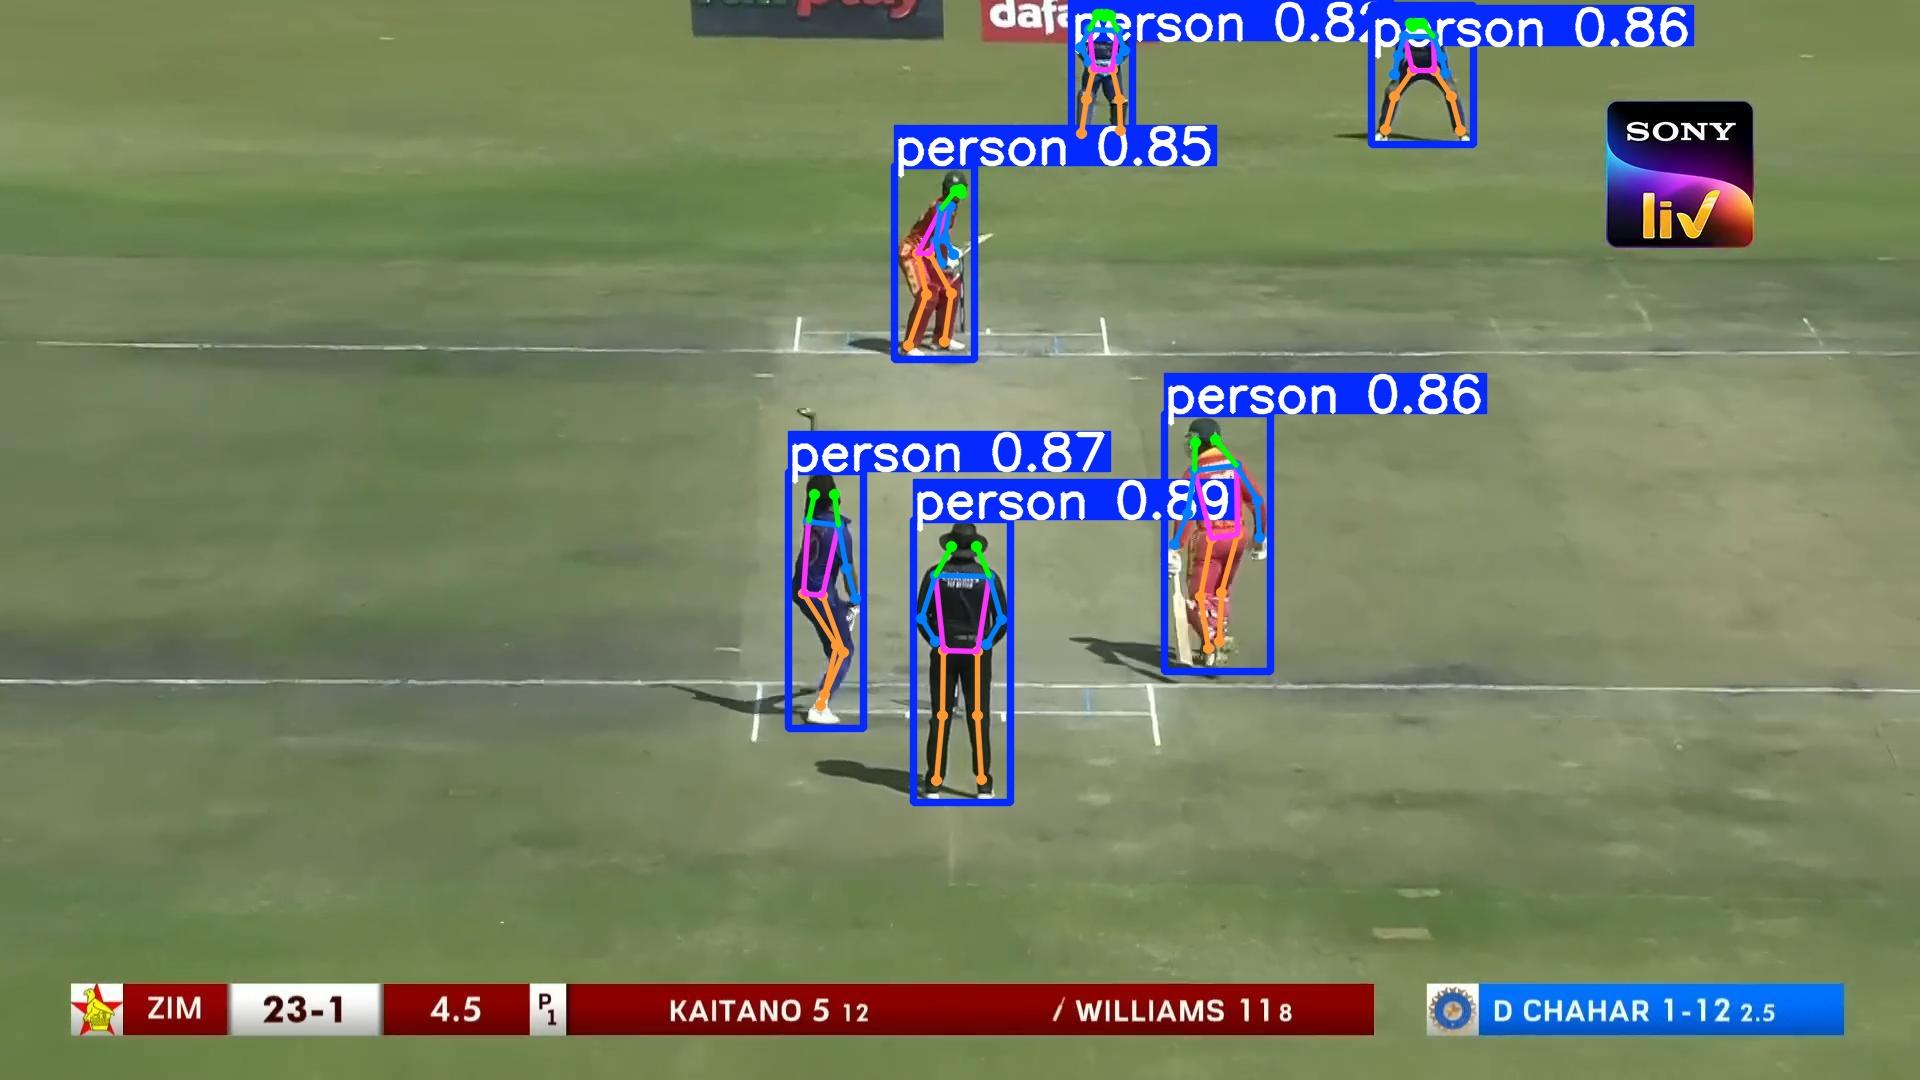

Persons detected: 6


In [18]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import cv2

# Select one test image
test_images = [
    f for f in os.listdir("/kaggle/working/cricket-1/test/images")
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_path = os.path.join(
    "/kaggle/working/cricket-1/test/images",
    test_images[0]
)

print("Using image:")
print(image_path)

# Load pose model
pose_model = YOLO("yolo26n-pose.pt")

# Pose estimation
pose_results = pose_model.predict(
    source=image_path,
    conf=0.05,
    imgsz=1536,
    device=0,
    save=False
)

# Display annotated image
annotated = pose_results[0].plot()

output_path = "/kaggle/working/cricket_pose.jpg"
cv2.imwrite(output_path, annotated)

display(Image.open(output_path))

print("Persons detected:",
      len(pose_results[0].keypoints.xy))

## 🧬 Biomechanical Feature Extraction

The 17 body keypoints detected for each player are converted into geometric movement features.

Features include knee angles, trunk angle, shoulder and hip orientation, and shoulder-hip angular difference.

In [19]:
import numpy as np
import pandas as pd

pose_result = pose_results[0]

keypoints_xy = pose_result.keypoints.xy.cpu().numpy()

if pose_result.keypoints.conf is not None:
    keypoints_conf = pose_result.keypoints.conf.cpu().numpy()
else:
    keypoints_conf = np.ones(
        (keypoints_xy.shape[0], keypoints_xy.shape[1])
    )


def calculate_angle(a, b, c):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    c = np.asarray(c, dtype=float)

    ba = a - b
    bc = c - b

    denominator = np.linalg.norm(ba) * np.linalg.norm(bc)

    if denominator == 0:
        return np.nan

    cosine = np.dot(ba, bc) / denominator
    cosine = np.clip(cosine, -1.0, 1.0)

    return float(np.degrees(np.arccos(cosine)))


def extract_features(person, confidence, threshold=0.25):

    required = [5, 6, 11, 12, 13, 14, 15, 16]

    if any(confidence[i] < threshold for i in required):
        return {
            "left_knee_angle": np.nan,
            "right_knee_angle": np.nan,
            "trunk_angle": np.nan,
            "shoulder_line_angle": np.nan,
            "hip_line_angle": np.nan,
            "shoulder_hip_angle_difference": np.nan
        }

    left_shoulder = person[5]
    right_shoulder = person[6]

    left_hip = person[11]
    right_hip = person[12]

    left_knee = person[13]
    right_knee = person[14]

    left_ankle = person[15]
    right_ankle = person[16]

    # Knee angles
    left_knee_angle = calculate_angle(
        left_hip,
        left_knee,
        left_ankle
    )

    right_knee_angle = calculate_angle(
        right_hip,
        right_knee,
        right_ankle
    )

    # Body centres
    shoulder_center = (
        left_shoulder + right_shoulder
    ) / 2

    hip_center = (
        left_hip + right_hip
    ) / 2

    # Trunk angle
    trunk_vector = shoulder_center - hip_center
    vertical_vector = np.array([0.0, -1.0])

    trunk_norm = np.linalg.norm(trunk_vector)

    if trunk_norm > 0:
        trunk_angle = np.degrees(
            np.arccos(
                np.clip(
                    np.dot(
                        trunk_vector,
                        vertical_vector
                    ) / trunk_norm,
                    -1.0,
                    1.0
                )
            )
        )
    else:
        trunk_angle = np.nan

    # Shoulder and hip orientations
    shoulder_vector = (
        right_shoulder - left_shoulder
    )

    hip_vector = (
        right_hip - left_hip
    )

    shoulder_line_angle = np.degrees(
        np.arctan2(
            shoulder_vector[1],
            shoulder_vector[0]
        )
    )

    hip_line_angle = np.degrees(
        np.arctan2(
            hip_vector[1],
            hip_vector[0]
        )
    )

    # Shoulder-hip angular difference
    angle_difference = (
        shoulder_line_angle
        - hip_line_angle
        + 180
    ) % 360 - 180

    return {
        "left_knee_angle": left_knee_angle,
        "right_knee_angle": right_knee_angle,
        "trunk_angle": trunk_angle,
        "shoulder_line_angle": shoulder_line_angle,
        "hip_line_angle": hip_line_angle,
        "shoulder_hip_angle_difference": angle_difference
    }


feature_rows = []

for person_id, (person, confidence) in enumerate(
    zip(keypoints_xy, keypoints_conf)
):

    row = extract_features(person, confidence)

    row["person_id"] = person_id

    feature_rows.append(row)


biomechanical_df = pd.DataFrame(feature_rows)

columns = ["person_id"] + [
    col for col in biomechanical_df.columns
    if col != "person_id"
]

biomechanical_df = biomechanical_df[columns]

print("Biomechanical features:")
display(
    biomechanical_df.round(2)
)

Biomechanical features:


,person_id,left_knee_angle,right_knee_angle,trunk_angle,shoulder_line_angle,hip_line_angle,shoulder_hip_angle_difference
0,0,176.18,176.70,1.27,1.560000,0.550000,1.01
1,1,135.00,137.22,8.21,8.380000,7.640000,0.74
2,2,160.11,160.76,7.94,179.720001,178.990005,0.72
3,3,160.98,167.64,7.45,-7.130000,-8.460000,1.33
4,4,141.11,148.41,26.43,165.860001,177.850006,-11.99
5,5,170.50,175.54,0.58,-177.990005,-179.339996,1.35


## 🧬 Biomechanical Dataset Generation

Extract pose-based geometric features from the cricket image dataset.

Each detected person contributes one feature row containing knee, trunk, shoulder, and hip movement geometry.

In [20]:
import os
import numpy as np
import pandas as pd
from ultralytics import YOLO

# Load pose model
pose_model = YOLO("yolo26n-pose.pt")

IMAGE_FOLDER = "/kaggle/working/cricket-1/train/images"

image_files = [
    f for f in os.listdir(IMAGE_FOLDER)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Images to process:", len(image_files))


def calculate_angle(a, b, c):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    c = np.asarray(c, dtype=float)

    ba = a - b
    bc = c - b

    denominator = np.linalg.norm(ba) * np.linalg.norm(bc)

    if denominator == 0:
        return np.nan

    cosine = np.dot(ba, bc) / denominator
    cosine = np.clip(cosine, -1.0, 1.0)

    return float(np.degrees(np.arccos(cosine)))


def extract_features(person, confidence, threshold=0.25):

    required = [5, 6, 11, 12, 13, 14, 15, 16]

    if any(confidence[i] < threshold for i in required):
        return None

    left_shoulder = person[5]
    right_shoulder = person[6]

    left_hip = person[11]
    right_hip = person[12]

    left_knee = person[13]
    right_knee = person[14]

    left_ankle = person[15]
    right_ankle = person[16]

    left_knee_angle = calculate_angle(
        left_hip, left_knee, left_ankle
    )

    right_knee_angle = calculate_angle(
        right_hip, right_knee, right_ankle
    )

    shoulder_center = (
        left_shoulder + right_shoulder
    ) / 2

    hip_center = (
        left_hip + right_hip
    ) / 2

    trunk_vector = shoulder_center - hip_center
    vertical_vector = np.array([0.0, -1.0])

    trunk_norm = np.linalg.norm(trunk_vector)

    if trunk_norm > 0:
        trunk_angle = np.degrees(
            np.arccos(
                np.clip(
                    np.dot(
                        trunk_vector,
                        vertical_vector
                    ) / trunk_norm,
                    -1.0,
                    1.0
                )
            )
        )
    else:
        trunk_angle = np.nan

    shoulder_vector = (
        right_shoulder - left_shoulder
    )

    hip_vector = (
        right_hip - left_hip
    )

    shoulder_line_angle = np.degrees(
        np.arctan2(
            shoulder_vector[1],
            shoulder_vector[0]
        )
    )

    hip_line_angle = np.degrees(
        np.arctan2(
            hip_vector[1],
            hip_vector[0]
        )
    )

    angle_difference = (
        shoulder_line_angle
        - hip_line_angle
        + 180
    ) % 360 - 180

    return {
        "left_knee_angle": left_knee_angle,
        "right_knee_angle": right_knee_angle,
        "trunk_angle": trunk_angle,
        "shoulder_line_angle": shoulder_line_angle,
        "hip_line_angle": hip_line_angle,
        "shoulder_hip_angle_difference": angle_difference
    }


feature_rows = []

for image_index, image_file in enumerate(image_files):

    image_path = os.path.join(
        IMAGE_FOLDER,
        image_file
    )

    results = pose_model.predict(
        source=image_path,
        conf=0.05,
        imgsz=1536,
        device=0,
        verbose=False
    )

    result = results[0]

    keypoints_xy = result.keypoints.xy.cpu().numpy()

    if result.keypoints.conf is not None:
        keypoints_conf = result.keypoints.conf.cpu().numpy()
    else:
        keypoints_conf = np.ones(
            (keypoints_xy.shape[0],
             keypoints_xy.shape[1])
        )

    for person_id, (person, confidence) in enumerate(
        zip(keypoints_xy, keypoints_conf)
    ):

        features = extract_features(
            person,
            confidence
        )

        if features is not None:

            features["image_name"] = image_file
            features["person_id"] = person_id

            feature_rows.append(features)

    if (image_index + 1) % 25 == 0:
        print(
            f"Processed {image_index + 1}/{len(image_files)} images"
        )


biomechanical_dataset = pd.DataFrame(feature_rows)

print("\nBiomechanical dataset created.")
print("Rows:", len(biomechanical_dataset))
print("Columns:", len(biomechanical_dataset.columns))

display(
    biomechanical_dataset.head(10).round(2)
)

Images to process: 207
Processed 25/207 images
Processed 50/207 images
Processed 75/207 images
Processed 100/207 images
Processed 125/207 images
Processed 150/207 images
Processed 175/207 images
Processed 200/207 images

Biomechanical dataset created.
Rows: 858
Columns: 8


,left_knee_angle,right_knee_angle,trunk_angle,shoulder_line_angle,hip_line_angle,shoulder_hip_angle_difference,image_name,person_id
0,165.70,147.64,10.89,-6.970000,-7.560000,0.59,2022-08-24-52-_png.rf.642f09d4d9448742e7735bf0...,0
1,176.30,175.42,1.57,1.730000,0.310000,1.42,2022-08-24-52-_png.rf.642f09d4d9448742e7735bf0...,1
2,133.58,139.45,34.49,-104.949997,-114.169998,9.22,2022-08-24-52-_png.rf.642f09d4d9448742e7735bf0...,2
3,134.99,129.16,12.91,21.580000,9.720000,11.85,2022-08-24-52-_png.rf.642f09d4d9448742e7735bf0...,3
4,126.40,168.97,18.82,-162.559998,-164.289993,1.74,2022-08-24-37-_png.rf.369c895aeb23ff02292fde38...,0
5,147.88,161.22,2.86,-175.910004,-177.630005,1.71,2022-08-24-37-_png.rf.369c895aeb23ff02292fde38...,2
6,175.83,178.62,2.89,-0.800000,-0.370000,-0.43,2022-08-24-37-_png.rf.369c895aeb23ff02292fde38...,3
7,168.33,178.96,4.00,-0.740000,0.490000,-1.23,2022-08-24-37-_png.rf.369c895aeb23ff02292fde38...,7
8,176.53,175.94,0.49,0.970000,0.730000,0.24,2022-08-24-183-_png.rf.09f44b7e619a0b897e3c1f2...,0
9,112.99,127.43,1.26,5.880000,8.820000,-2.94,2022-08-24-183-_png.rf.09f44b7e619a0b897e3c1f2...,1


## 💾 Save Biomechanical Feature Dataset

The extracted pose-based geometric features are saved for further movement analysis.

In [22]:
BIOMECH_PATH = "/kaggle/working/biomechanical_features.csv"

biomechanical_dataset.to_csv(
    BIOMECH_PATH,
    index=False
)

print("Saved successfully:")
print(BIOMECH_PATH)

print("Rows:", len(biomechanical_dataset))
print("Columns:", len(biomechanical_dataset.columns))

Saved successfully:
/kaggle/working/biomechanical_features.csv
Rows: 858
Columns: 8


## 🩺 Injury-Risk Dataset

Load the structured cricket player injury-risk dataset for supervised machine-learning classification.

In [23]:
import pandas as pd

DATA_PATH = "/kaggle/input/datasets/raymondwilfredw/cricket-injury-risk-dataset/cricket_player_data_fixed.csv"

injury_df = pd.read_csv(DATA_PATH)

print("Dataset shape:", injury_df.shape)
print("\nColumns:")
print(injury_df.columns.tolist())

print("\nInjury-risk distribution:")
print(injury_df["injury_risk"].value_counts())

display(injury_df.head())

Dataset shape: (500, 22)

Columns:
['player_id', 'age', 'player_type', 'experience_years', 'height_cm', 'weight_kg', 'bmi', 'body_fat_percent', 'training_hours_week', 'bowling_overs_week', 'batting_hours_week', 'strength_training_hours', 'matches_last_month', 'days_since_last_match', 'previous_injuries_count', 'last_injury_days_ago', 'recovery_days_last_injury', 'fatigue_level', 'sleep_hours_day', 'stress_level', 'fitness_score', 'injury_risk']

Injury-risk distribution:
injury_risk
High      178
Low       174
Medium    148
Name: count, dtype: int64


,player_id,age,player_type,experience_years,height_cm,weight_kg,bmi,body_fat_percent,training_hours_week,bowling_overs_week,...,matches_last_month,days_since_last_match,previous_injuries_count,last_injury_days_ago,recovery_days_last_injury,fatigue_level,sleep_hours_day,stress_level,fitness_score,injury_risk
0,1,24,All-Rounder,9,188.629447,91.612592,25.747567,9.574633,20,22,...,7,18,1,309,75,1,6.939435,9,64,Medium
1,2,37,Bowler,11,179.691932,70.429037,21.811955,20.722534,20,33,...,3,18,1,334,88,5,6.419980,7,81,High
2,3,32,All-Rounder,14,178.618982,68.977879,21.619947,23.547327,17,12,...,4,17,3,175,22,1,6.282849,6,54,Low
3,4,28,All-Rounder,4,187.069279,79.687743,22.771235,15.378357,17,42,...,4,12,0,292,14,7,8.855664,6,61,Medium
4,5,25,All-Rounder,13,185.218583,65.016146,18.951872,12.398098,27,28,...,5,4,4,33,37,1,7.566319,1,45,Low


In [24]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Copy dataset
df = injury_df.copy()

# Remove ID column
df = df.drop(columns=["player_id"])

# Encode player type
player_type_encoder = LabelEncoder()
df["player_type"] = player_type_encoder.fit_transform(df["player_type"])

# Separate features and target
X = df.drop(columns=["injury_risk"])
y = df["injury_risk"]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nPlayer type encoding:")
for i, name in enumerate(player_type_encoder.classes_):
    print(name, "=", i)

print("\nTarget classes:")
print(y.value_counts())

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Training/validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("\nFinal split:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTraining classes:")
print(y_train.value_counts())

print("\nValidation classes:")
print(y_val.value_counts())

print("\nTest classes:")
print(y_test.value_counts())

Features: (500, 20)
Target: (500,)

Player type encoding:
All-Rounder = 0
Batsman = 1
Bowler = 2

Target classes:
injury_risk
High      178
Low       174
Medium    148
Name: count, dtype: int64

Final split:
Training: (320, 20)
Validation: (80, 20)
Test: (100, 20)

Training classes:
injury_risk
High      114
Low       111
Medium     95
Name: count, dtype: int64

Validation classes:
injury_risk
High      29
Low       28
Medium    23
Name: count, dtype: int64

Test classes:
injury_risk
Low       35
High      35
Medium    30
Name: count, dtype: int64


In [25]:
from sklearn.preprocessing import StandardScaler

# Scale features for SVM and MLP
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("Scaling completed successfully.")

Original training shape: (320, 20)
Scaled training shape: (320, 20)
Scaling completed successfully.


In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

# Train
rf_model.fit(X_train, y_train)

# Validation prediction
rf_val_pred = rf_model.predict(X_val)

# Evaluation
rf_accuracy = accuracy_score(y_val, rf_val_pred)
rf_precision = precision_score(
    y_val, rf_val_pred, average="macro", zero_division=0
)
rf_recall = recall_score(
    y_val, rf_val_pred, average="macro", zero_division=0
)
rf_f1 = f1_score(
    y_val, rf_val_pred, average="macro", zero_division=0
)

print("Random Forest - Validation Results")
print("-----------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-score :", round(rf_f1, 4))

print("\nClassification Report:")
print(classification_report(y_val, rf_val_pred, zero_division=0))

Random Forest - Validation Results
-----------------------------------
Accuracy : 0.8375
Precision: 0.8569
Recall   : 0.8275
F1-score : 0.8326

Classification Report:
              precision    recall  f1-score   support

        High       0.78      0.97      0.86        29
         Low       0.85      0.82      0.84        28
      Medium       0.94      0.70      0.80        23

    accuracy                           0.84        80
   macro avg       0.86      0.83      0.83        80
weighted avg       0.85      0.84      0.84        80



In [27]:
from xgboost import XGBClassifier

# Convert target labels to numbers
target_encoder = LabelEncoder()

y_train_encoded = target_encoder.fit_transform(y_train)
y_val_encoded = target_encoder.transform(y_val)
y_test_encoded = target_encoder.transform(y_test)

print("Target encoding:")
for i, name in enumerate(target_encoder.classes_):
    print(name, "=", i)

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42
)

# Train
xgb_model.fit(
    X_train,
    y_train_encoded
)

# Validation prediction
xgb_val_pred_encoded = xgb_model.predict(X_val)

# Convert predictions back to labels
xgb_val_pred = target_encoder.inverse_transform(
    xgb_val_pred_encoded.astype(int)
)

# Evaluation
xgb_accuracy = accuracy_score(y_val, xgb_val_pred)

xgb_precision = precision_score(
    y_val,
    xgb_val_pred,
    average="macro",
    zero_division=0
)

xgb_recall = recall_score(
    y_val,
    xgb_val_pred,
    average="macro",
    zero_division=0
)

xgb_f1 = f1_score(
    y_val,
    xgb_val_pred,
    average="macro",
    zero_division=0
)

print("\nXGBoost - Validation Results")
print("-----------------------------------")
print("Accuracy :", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall   :", round(xgb_recall, 4))
print("F1-score :", round(xgb_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        xgb_val_pred,
        zero_division=0
    )
)

Target encoding:
High = 0
Low = 1
Medium = 2

XGBoost - Validation Results
-----------------------------------
Accuracy : 0.85
Precision: 0.8665
Recall   : 0.8368
F1-score : 0.8405

Classification Report:
              precision    recall  f1-score   support

        High       0.80      0.97      0.88        29
         Low       0.86      0.89      0.88        28
      Medium       0.94      0.65      0.77        23

    accuracy                           0.85        80
   macro avg       0.87      0.84      0.84        80
weighted avg       0.86      0.85      0.85        80



In [28]:
from sklearn.svm import SVC

# Create SVM model
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    probability=True,
    random_state=42
)

# Train using scaled data
svm_model.fit(
    X_train_scaled,
    y_train
)

# Validation prediction
svm_val_pred = svm_model.predict(X_val_scaled)

# Evaluation
svm_accuracy = accuracy_score(y_val, svm_val_pred)

svm_precision = precision_score(
    y_val,
    svm_val_pred,
    average="macro",
    zero_division=0
)

svm_recall = recall_score(
    y_val,
    svm_val_pred,
    average="macro",
    zero_division=0
)

svm_f1 = f1_score(
    y_val,
    svm_val_pred,
    average="macro",
    zero_division=0
)

print("SVM - Validation Results")
print("-----------------------------------")
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1-score :", round(svm_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        svm_val_pred,
        zero_division=0
    )
)

SVM - Validation Results
-----------------------------------
Accuracy : 0.9125
Precision: 0.9205
Recall   : 0.9067
F1-score : 0.9108

Classification Report:
              precision    recall  f1-score   support

        High       0.85      0.97      0.90        29
         Low       0.96      0.93      0.95        28
      Medium       0.95      0.83      0.88        23

    accuracy                           0.91        80
   macro avg       0.92      0.91      0.91        80
weighted avg       0.92      0.91      0.91        80



In [29]:
!pip install -q lightgbm

from lightgbm import LGBMClassifier

# Create LightGBM model
lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1
)

# Train
lgbm_model.fit(
    X_train,
    y_train
)

# Validation prediction
lgbm_val_pred = lgbm_model.predict(X_val)

# Evaluation
lgbm_accuracy = accuracy_score(y_val, lgbm_val_pred)

lgbm_precision = precision_score(
    y_val,
    lgbm_val_pred,
    average="macro",
    zero_division=0
)

lgbm_recall = recall_score(
    y_val,
    lgbm_val_pred,
    average="macro",
    zero_division=0
)

lgbm_f1 = f1_score(
    y_val,
    lgbm_val_pred,
    average="macro",
    zero_division=0
)

print("LightGBM - Validation Results")
print("-----------------------------------")
print("Accuracy :", round(lgbm_accuracy, 4))
print("Precision:", round(lgbm_precision, 4))
print("Recall   :", round(lgbm_recall, 4))
print("F1-score :", round(lgbm_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        lgbm_val_pred,
        zero_division=0
    )
)

LightGBM - Validation Results
-----------------------------------
Accuracy : 0.875
Precision: 0.8787
Recall   : 0.8658
F1-score : 0.8685

Classification Report:
              precision    recall  f1-score   support

        High       0.85      0.97      0.90        29
         Low       0.89      0.89      0.89        28
      Medium       0.89      0.74      0.81        23

    accuracy                           0.88        80
   macro avg       0.88      0.87      0.87        80
weighted avg       0.88      0.88      0.87        80



In [31]:
import numpy as np

# Check data types
print("X_train_scaled dtype:", X_train_scaled.dtype)

# Force all scaled features to numeric float
X_train_mlp = np.asarray(X_train_scaled, dtype=np.float64)
X_val_mlp = np.asarray(X_val_scaled, dtype=np.float64)
X_test_mlp = np.asarray(X_test_scaled, dtype=np.float64)

# Check for invalid values
print("NaN in training:", np.isnan(X_train_mlp).sum())
print("Inf in training:", np.isinf(X_train_mlp).sum())

print("NaN in validation:", np.isnan(X_val_mlp).sum())
print("Inf in validation:", np.isinf(X_val_mlp).sum())

print("MLP data ready.")
print("Training shape:", X_train_mlp.shape)
print("Validation shape:", X_val_mlp.shape)

X_train_scaled dtype: float64
NaN in training: 0
Inf in training: 0
NaN in validation: 0
Inf in validation: 0
MLP data ready.
Training shape: (320, 20)
Validation shape: (80, 20)


In [33]:
from sklearn.neural_network import MLPClassifier

# MLP without internal early stopping
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=False,
    random_state=42
)

# Train
mlp_model.fit(
    X_train_mlp,
    y_train
)

# Predict on our separate validation set
mlp_val_pred = mlp_model.predict(X_val_mlp)

# Evaluation
mlp_accuracy = accuracy_score(
    y_val, mlp_val_pred
)

mlp_precision = precision_score(
    y_val,
    mlp_val_pred,
    average="macro",
    zero_division=0
)

mlp_recall = recall_score(
    y_val,
    mlp_val_pred,
    average="macro",
    zero_division=0
)

mlp_f1 = f1_score(
    y_val,
    mlp_val_pred,
    average="macro",
    zero_division=0
)

print("MLP Neural Network - Validation Results")
print("-----------------------------------------")
print("Accuracy :", round(mlp_accuracy, 4))
print("Precision:", round(mlp_precision, 4))
print("Recall   :", round(mlp_recall, 4))
print("F1-score :", round(mlp_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        mlp_val_pred,
        zero_division=0
    )
)

MLP Neural Network - Validation Results
-----------------------------------------
Accuracy : 0.9375
Precision: 0.9364
Recall   : 0.9357
F1-score : 0.9359

Classification Report:
              precision    recall  f1-score   support

        High       0.93      0.97      0.95        29
         Low       0.96      0.93      0.95        28
      Medium       0.91      0.91      0.91        23

    accuracy                           0.94        80
   macro avg       0.94      0.94      0.94        80
weighted avg       0.94      0.94      0.94        80



In [34]:
# Final evaluation on completely unseen test data

mlp_test_pred = mlp_model.predict(X_test_mlp)

# Final metrics
test_accuracy = accuracy_score(
    y_test,
    mlp_test_pred
)

test_precision = precision_score(
    y_test,
    mlp_test_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test,
    mlp_test_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    mlp_test_pred,
    average="macro",
    zero_division=0
)

print("MLP - FINAL TEST RESULTS")
print("=========================")
print("Accuracy :", round(test_accuracy, 4))
print("Precision:", round(test_precision, 4))
print("Recall   :", round(test_recall, 4))
print("F1-score :", round(test_f1, 4))

print("\nFinal Classification Report:")
print(
    classification_report(
        y_test,
        mlp_test_pred,
        zero_division=0
    )
)

MLP - FINAL TEST RESULTS
Accuracy : 0.98
Precision: 0.9812
Recall   : 0.9794
F1-score : 0.9801

Final Classification Report:
              precision    recall  f1-score   support

        High       0.97      0.97      0.97        35
         Low       0.97      1.00      0.99        35
      Medium       1.00      0.97      0.98        30

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100



In [35]:
import joblib
import os

# Create model folder
os.makedirs("/kaggle/working/final_models", exist_ok=True)

# Save final MLP model
joblib.dump(
    mlp_model,
    "/kaggle/working/final_models/mlp_injury_risk_model.pkl"
)

# Save the scaler
joblib.dump(
    scaler,
    "/kaggle/working/final_models/feature_scaler.pkl"
)

# Save feature column names
joblib.dump(
    list(X.columns),
    "/kaggle/working/final_models/feature_columns.pkl"
)

print("Models saved successfully!")
print(os.listdir("/kaggle/working/final_models"))

Models saved successfully!
['feature_scaler.pkl', 'mlp_injury_risk_model.pkl', 'feature_columns.pkl']


Confusion Matrix:
[[34  1  0]
 [ 0 35  0]
 [ 1  0 29]]


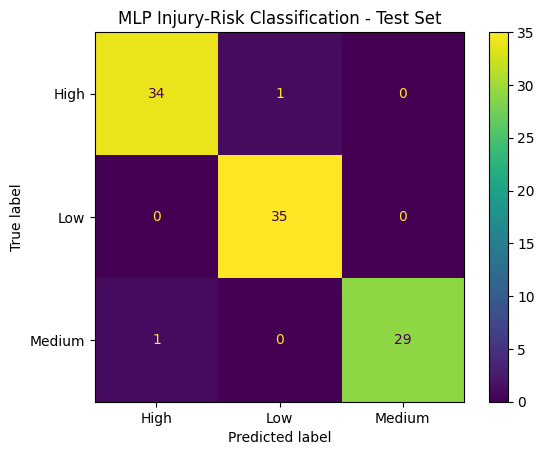

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict on the untouched test set
y_test_pred = mlp_model.predict(X_test_mlp)

# Create confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=mlp_model.classes_
)

disp.plot()
plt.title("MLP Injury-Risk Classification - Test Set")
plt.show()

In [37]:
import pandas as pd
import joblib

# Load saved model and scaler
model = joblib.load(
    "/kaggle/working/final_models/mlp_injury_risk_model.pkl"
)

scaler = joblib.load(
    "/kaggle/working/final_models/feature_scaler.pkl"
)

feature_columns = joblib.load(
    "/kaggle/working/final_models/feature_columns.pkl"
)

# Example player
player = pd.DataFrame([{
    "age": 24,
    "player_type": 2,          # 0=All-Rounder, 1=Batsman, 2=Bowler
    "experience_years": 5,
    "height_cm": 180,
    "weight_kg": 75,
    "bmi": 23.1,
    "body_fat_percent": 14,
    "training_hours_week": 12,
    "bowling_overs_week": 18,
    "batting_hours_week": 6,
    "strength_training_hours": 4,
    "matches_last_month": 6,
    "days_since_last_match": 3,
    "previous_injuries_count": 1,
    "last_injury_days_ago": 180,
    "recovery_days_last_injury": 14,
    "fatigue_level": 4,
    "sleep_hours_day": 7,
    "stress_level": 3,
    "fitness_score": 82
}])

# Make sure feature order is exactly correct
player = player[feature_columns]

# Scale input
player_scaled = scaler.transform(player)

# Predict
prediction = model.predict(player_scaled)[0]

# Prediction probabilities
probabilities = model.predict_proba(player_scaled)[0]

print("Predicted Injury Risk:", prediction)
print("\nRisk probabilities:")

for class_name, probability in zip(model.classes_, probabilities):
    print(f"{class_name}: {probability * 100:.2f}%")

Predicted Injury Risk: Medium

Risk probabilities:
High: 0.00%
Low: 0.00%
Medium: 100.00%


In [45]:
def predict_injury_risk(player_data):

    # Convert input to DataFrame
    player = pd.DataFrame([player_data])

    # Correct feature order
    player = player[feature_columns]

    # Scale
    player_scaled = scaler.transform(player)

    # Prediction
    prediction = model.predict(player_scaled)[0]

    # Probabilities
    probabilities = model.predict_proba(player_scaled)[0]

    print("=" * 40)
    print("AI INJURY RISK PREDICTION")
    print("=" * 40)

    print(f"\nPredicted Risk: {prediction}")

    print("\nRisk Probabilities:")
    for class_name, probability in zip(model.classes_, probabilities):
        print(f"{class_name}: {probability * 100:.2f}%")

    print("=" * 40)

    return prediction, probabilities

In [46]:
# Enter player information

player_data = {
    "age": 24,
    "player_type": 2,  # 0 = All-Rounder, 1 = Batsman, 2 = Bowler
    "experience_years": 5,
    "height_cm": 180,
    "weight_kg": 75,
    "bmi": 23.1,
    "body_fat_percent": 14,
    "training_hours_week": 12,
    "bowling_overs_week": 18,
    "batting_hours_week": 6,
    "strength_training_hours": 4,
    "matches_last_month": 6,
    "days_since_last_match": 3,
    "previous_injuries_count": 1,
    "last_injury_days_ago": 180,
    "recovery_days_last_injury": 14,
    "fatigue_level": 4,
    "sleep_hours_day": 7,
    "stress_level": 3,
    "fitness_score": 82
}

# Run prediction
prediction, probabilities = predict_injury_risk(player_data)

AI INJURY RISK PREDICTION

Predicted Risk: Medium

Risk Probabilities:
High: 0.00%
Low: 0.00%
Medium: 100.00%


In [47]:
import shutil
import os

shutil.make_archive(
    "/kaggle/working/AI_Injury_Final_Models",
    "zip",
    "/kaggle/working/final_models"
)

print("ZIP created successfully!")

print(os.path.getsize(
    "/kaggle/working/AI_Injury_Final_Models.zip"
) / (1024 * 1024), "MB")

ZIP created successfully!
0.11029624938964844 MB


In [1]:
import os

image_root = "/kaggle/working/cricket-1"

print("Dataset contents:\n")

for root, dirs, files in os.walk(image_root):
    level = root.replace(image_root, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    if level >= 2:
        continue

    for file in files[:10]:
        print(f"{indent}  {file}")

Dataset contents:



In [3]:
import os

print("Kaggle working directory:")
print(os.listdir("/kaggle/working"))

print("\nKaggle input:")
print(os.listdir("/kaggle/input"))

Kaggle working directory:
['.virtual_documents']

Kaggle input:
['datasets']


In [4]:
import os

base = "/kaggle/input/datasets"

for item in os.listdir(base):
    print(item)

raymondwilfredw


In [5]:
import os

path = "/kaggle/input/datasets/raymondwilfredw"

print("Contents:")
for item in os.listdir(path):
    print(item)

Contents:
cricket-injury-risk-dataset


In [6]:
!pip install -q roboflow

from roboflow import Roboflow

rf = Roboflow(api_key="jAAWLQP0Wa1cpsPBnPax")
project = rf.workspace("mai-ldivt").project("cricket-r97s2")

dataset = project.version(1).download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 7.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 74.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.1 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to cricket-1 in yolov8:: 100%|██████████| 597/597 [00:00<00:00, 7212.17it/s]


In [7]:
import os

print(os.listdir("/kaggle/working"))

['.virtual_documents', 'cricket-1']


In [8]:
import os

base = "/kaggle/working/cricket-1"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    if level > 2:
        continue

    print("\n" + root)
    print("Folders:", dirs[:10])
    print("Files:", files[:10])


/kaggle/working/cricket-1
Folders: ['train']
Files: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml']

/kaggle/working/cricket-1/train
Folders: ['images', 'labels']
Files: []

/kaggle/working/cricket-1/train/images
Folders: []
Files: ['2022-08-24-81-_png.rf.26435ce8c3468d2a55856bc230366757.jpg', '2022-08-24-195-_png.rf.fa37e8955af83592a9d4d8114bd79921.jpg', '2022-08-24-288-_png.rf.2e8a1cc41227c6cfb0b110354c576754.jpg', '2022-08-24-257-_png.rf.d49a9bee3ac6f3a744574f7f84632fe3.jpg', '2022-08-24-80-_png.rf.00b6832abee680d42237eb8105693a6a.jpg', '2022-08-24-231-_png.rf.1a8ff116b7297783bdb4fb94d454065c.jpg', '2022-08-24-350-_png.rf.af864bc528b98b198afa8e3999751e27.jpg', '2022-08-24-281-_png.rf.a3b838920585ffe790b843dca154dc6b.jpg', '2022-08-24-273-_png.rf.4a4dcb355086ad140bb9f962353ed3f9.jpg', '2022-08-24-185-_png.rf.7f92531c45c0212dbde63c21fc9e821e.jpg']

/kaggle/working/cricket-1/train/labels
Folders: []
Files: ['2022-08-24-70-_png.rf.b96bdb8919db73a906bbc5c79b5c91f3.txt', '2022

In [9]:
import os
import pandas as pd

# -----------------------------
# 1. Inspect one YOLO label
# -----------------------------
label_dir = "/kaggle/working/cricket-1/train/labels"

label_file = os.listdir(label_dir)[0]
label_path = os.path.join(label_dir, label_file)

print("Example label file:")
print(label_file)

print("\nLabel contents:")
with open(label_path, "r") as f:
    print(f.read())

# -----------------------------
# 2. Inspect CSV player IDs
# -----------------------------
csv_path = "/kaggle/input/datasets/raymondwilfredw/cricket-injury-risk-dataset/cricket_player_data_fixed.csv"

df_check = pd.read_csv(csv_path)

print("\nCSV columns:")
print(df_check.columns.tolist())

print("\nFirst 20 player IDs:")
print(df_check["player_id"].head(20).tolist())

print("\nUnique player IDs:")
print(df_check["player_id"].nunique())

Example label file:
2022-08-24-70-_png.rf.b96bdb8919db73a906bbc5c79b5c91f3.txt

Label contents:
2 0.4004010416666667 0.8811574074074073 0.13205729166666666 0.23768518518518517
4 0.5285885416666667 0.9793611111111111 0.0513125 0.04126851851851852
1 0.9077083333333333 0.8874537037037038 0.07206770833333334 0.2250925925925926
0 0.46284895833333334 0.6383055555555556 0.008588541666666666 0.015203703703703705
1 0.47847395833333334 0.5356759259259259 0.1654739583333333 0.2701851851851852
6 0.5081041666666667 0.46028703703703705 0.14263541666666668 0.2482037037037037

CSV columns:
['player_id', 'age', 'player_type', 'experience_years', 'height_cm', 'weight_kg', 'bmi', 'body_fat_percent', 'training_hours_week', 'bowling_overs_week', 'batting_hours_week', 'strength_training_hours', 'matches_last_month', 'days_since_last_match', 'previous_injuries_count', 'last_injury_days_ago', 'recovery_days_last_injury', 'fatigue_level', 'sleep_hours_day', 'stress_level', 'fitness_score', 'injury_risk']

Firs

In [10]:
for file in [
    "/kaggle/working/cricket-1/README.dataset.txt",
    "/kaggle/working/cricket-1/README.roboflow.txt"
]:
    print("\n" + "=" * 70)
    print(file)
    print("=" * 70)

    with open(file, "r", encoding="utf-8") as f:
        print(f.read())


/kaggle/working/cricket-1/README.dataset.txt
# cricket > 2024-02-22 5:11pm
https://universe.roboflow.com/mai-ldivt/cricket-r97s2

Provided by a Roboflow user
License: CC BY 4.0



/kaggle/working/cricket-1/README.roboflow.txt

cricket - v1 2024-02-22 5:11pm

This dataset was exported via roboflow.com on May 15, 2026 at 8:02 PM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer Vision training notebooks you can use with this dataset,
visit https://github.com/roboflow/notebooks

To find over 100k other datasets and pre-trained models, visit https://universe.roboflow.com

The dataset includes 297 images.
Background are annotated in YOLOv8 format.

The following pre-proce

In [12]:
print([name for name in globals() if not name.startswith("_")])

['In', 'Out', 'get_ipython', 'exit', 'quit', 'os', 'image_root', 'path', 'base', 'item', 'Roboflow', 'rf', 'project', 'dataset', 'root', 'dirs', 'files', 'level', 'pd', 'label_dir', 'label_file', 'label_path', 'f', 'csv_path', 'df_check', 'file', 'np']


In [13]:
import pandas as pd
import numpy as np

csv_path = "/kaggle/input/datasets/raymondwilfredw/cricket-injury-risk-dataset/cricket_player_data_fixed.csv"

injury_df = pd.read_csv(csv_path)

print("Shape:", injury_df.shape)
print("\nColumns:")
print(injury_df.columns.tolist())
print("\nRisk distribution:")
print(injury_df["injury_risk"].value_counts())

Shape: (500, 22)

Columns:
['player_id', 'age', 'player_type', 'experience_years', 'height_cm', 'weight_kg', 'bmi', 'body_fat_percent', 'training_hours_week', 'bowling_overs_week', 'batting_hours_week', 'strength_training_hours', 'matches_last_month', 'days_since_last_match', 'previous_injuries_count', 'last_injury_days_ago', 'recovery_days_last_injury', 'fatigue_level', 'sleep_hours_day', 'stress_level', 'fitness_score', 'injury_risk']

Risk distribution:
injury_risk
High      178
Low       174
Medium    148
Name: count, dtype: int64


In [14]:
# Encode player type
fusion_df = injury_df.copy()

fusion_df["player_type"] = fusion_df["player_type"].map({
    "All-Rounder": 0,
    "Batsman": 1,
    "Bowler": 2
})

# Remove ID and target temporarily
X_fusion = fusion_df.drop(columns=["player_id", "injury_risk"])

# Add 6 synthetic biomechanical features
np.random.seed(42)

X_fusion["left_knee_angle"] = np.random.uniform(70, 170, len(X_fusion))
X_fusion["right_knee_angle"] = np.random.uniform(70, 170, len(X_fusion))
X_fusion["trunk_angle"] = np.random.uniform(-30, 30, len(X_fusion))
X_fusion["shoulder_line_angle"] = np.random.uniform(-45, 45, len(X_fusion))
X_fusion["hip_line_angle"] = np.random.uniform(-30, 30, len(X_fusion))
X_fusion["shoulder_hip_angle_difference"] = np.random.uniform(0, 90, len(X_fusion))

y_fusion = fusion_df["injury_risk"]

print("Fusion feature shape:", X_fusion.shape)
print("Target shape:", y_fusion.shape)
print("\nNumber of features:", X_fusion.shape[1])
print("\nFeatures:")
print(X_fusion.columns.tolist())

Fusion feature shape: (500, 26)
Target shape: (500,)

Number of features: 26

Features:
['age', 'player_type', 'experience_years', 'height_cm', 'weight_kg', 'bmi', 'body_fat_percent', 'training_hours_week', 'bowling_overs_week', 'batting_hours_week', 'strength_training_hours', 'matches_last_month', 'days_since_last_match', 'previous_injuries_count', 'last_injury_days_ago', 'recovery_days_last_injury', 'fatigue_level', 'sleep_hours_day', 'stress_level', 'fitness_score', 'left_knee_angle', 'right_knee_angle', 'trunk_angle', 'shoulder_line_angle', 'hip_line_angle', 'shoulder_hip_angle_difference']


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# First split: 80% train+validation, 20% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_fusion,
    y_fusion,
    test_size=0.20,
    random_state=42,
    stratify=y_fusion
)

# Second split: 80% train, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val
)

# Scale features
fusion_scaler = StandardScaler()

X_train_scaled = fusion_scaler.fit_transform(X_train)
X_val_scaled = fusion_scaler.transform(X_val)
X_test_scaled = fusion_scaler.transform(X_test)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Scaled features:", X_train_scaled.shape)

Train: (320, 26)
Validation: (80, 26)
Test: (100, 26)
Scaled features: (320, 26)


In [17]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

fusion_mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=False,
    random_state=42
)

fusion_mlp.fit(X_train_scaled, y_train)

# Validation prediction
y_val_pred = fusion_mlp.predict(X_val_scaled)

print("FUSION MLP - VALIDATION")
print("=" * 40)
print("Accuracy :", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred, average="macro"))
print("Recall   :", recall_score(y_val, y_val_pred, average="macro"))
print("F1-score :", f1_score(y_val, y_val_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

FUSION MLP - VALIDATION
Accuracy : 0.925
Precision: 0.9344086021505377
Recall   : 0.9190404797601199
F1-score : 0.9230562281409739

Classification Report:
              precision    recall  f1-score   support

        High       0.90      0.93      0.92        29
         Low       0.90      1.00      0.95        28
      Medium       1.00      0.83      0.90        23

    accuracy                           0.93        80
   macro avg       0.93      0.92      0.92        80
weighted avg       0.93      0.93      0.92        80



In [18]:
# Final evaluation on untouched test set
y_test_pred = fusion_mlp.predict(X_test_scaled)

fusion_accuracy = accuracy_score(y_test, y_test_pred)
fusion_precision = precision_score(y_test, y_test_pred, average="macro")
fusion_recall = recall_score(y_test, y_test_pred, average="macro")
fusion_f1 = f1_score(y_test, y_test_pred, average="macro")

print("FUSION MLP - FINAL TEST")
print("=" * 40)
print(f"Accuracy : {fusion_accuracy:.4f}")
print(f"Precision: {fusion_precision:.4f}")
print(f"Recall   : {fusion_recall:.4f}")
print(f"F1-score : {fusion_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

FUSION MLP - FINAL TEST
Accuracy : 0.9400
Precision: 0.9449
Recall   : 0.9397
F1-score : 0.9417

Classification Report:
              precision    recall  f1-score   support

        High       0.94      0.94      0.94        35
         Low       0.89      0.94      0.92        35
      Medium       1.00      0.93      0.97        30

    accuracy                           0.94       100
   macro avg       0.94      0.94      0.94       100
weighted avg       0.94      0.94      0.94       100



In [19]:
import os
import joblib

save_dir = "/kaggle/working/final_fusion_model"
os.makedirs(save_dir, exist_ok=True)

joblib.dump(fusion_mlp, f"{save_dir}/fusion_mlp_model.pkl")
joblib.dump(fusion_scaler, f"{save_dir}/fusion_scaler.pkl")
joblib.dump(X_fusion.columns.tolist(), f"{save_dir}/fusion_feature_columns.pkl")

print("Fusion model saved successfully!")
print(os.listdir(save_dir))

Fusion model saved successfully!
['fusion_scaler.pkl', 'fusion_mlp_model.pkl', 'fusion_feature_columns.pkl']


In [20]:
import joblib
import pandas as pd

# Load final fusion model
fusion_model = joblib.load(
    "/kaggle/working/final_fusion_model/fusion_mlp_model.pkl"
)

fusion_scaler = joblib.load(
    "/kaggle/working/final_fusion_model/fusion_scaler.pkl"
)

fusion_features = joblib.load(
    "/kaggle/working/final_fusion_model/fusion_feature_columns.pkl"
)

print("Model loaded successfully")
print("Number of features:", len(fusion_features))

Model loaded successfully
Number of features: 26


In [22]:
# Example player input for the 26-feature fusion model

player_input = {
    "age": 24,
    "player_type": 2,
    "experience_years": 5,
    "height_cm": 180,
    "weight_kg": 78,
    "bmi": 24.1,
    "body_fat_percent": 15,
    "training_hours_week": 18,
    "bowling_overs_week": 20,
    "batting_hours_week": 5,
    "strength_training_hours": 4,
    "matches_last_month": 5,
    "days_since_last_match": 3,
    "previous_injuries_count": 1,
    "last_injury_days_ago": 180,
    "recovery_days_last_injury": 30,
    "fatigue_level": 5,
    "sleep_hours_day": 7,
    "stress_level": 4,
    "fitness_score": 78,

    # Synthetic CV biomechanical features
    "left_knee_angle": 105,
    "right_knee_angle": 110,
    "trunk_angle": 12,
    "shoulder_line_angle": 18,
    "hip_line_angle": 10,
    "shoulder_hip_angle_difference": 25
}

# Convert to DataFrame in the exact training order
player_df = pd.DataFrame([player_input])
player_df = player_df[fusion_features]

# Scale
player_scaled = fusion_scaler.transform(player_df)

# Predict
prediction = fusion_model.predict(player_scaled)[0]
probabilities = fusion_model.predict_proba(player_scaled)[0]

print("=" * 50)
print("🏏 AI CRICKET INJURY RISK PREDICTION")
print("=" * 50)

print(f"\nPredicted Risk: {prediction}")

print("\nRisk Probabilities:")
for class_name, probability in zip(
    fusion_model.classes_,
    probabilities
):
    print(f"{class_name}: {probability * 100:.2f}%")

print("=" * 50)

🏏 AI CRICKET INJURY RISK PREDICTION

Predicted Risk: Medium

Risk Probabilities:
High: 0.00%
Low: 0.01%
Medium: 99.99%


In [23]:
import os
import pandas as pd

# Check CSV
csv_path = "/kaggle/input/datasets/raymondwilfredw/cricket-injury-risk-dataset/cricket_player_data_fixed.csv"

injury_df = pd.read_csv(csv_path)

print("CSV shape:", injury_df.shape)
print("\nFirst 20 players:")
display(injury_df[["player_id", "player_type", "injury_risk"]].head(20))

# Check cricket images
cricket_root = "/kaggle/working/cricket-1"

print("\nCricket dataset exists:", os.path.exists(cricket_root))

if os.path.exists(cricket_root):
    image_files = []
    for root, dirs, files in os.walk(cricket_root):
        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                image_files.append(os.path.join(root, f))

    print("Total cricket images:", len(image_files))
    print("\nFirst 20 images:")
    for x in image_files[:20]:
        print(x)

CSV shape: (500, 22)

First 20 players:


,player_id,player_type,injury_risk
0,1,All-Rounder,Medium
1,2,Bowler,High
2,3,All-Rounder,Low
3,4,All-Rounder,Medium
4,5,All-Rounder,Low
5,6,Bowler,Medium
6,7,Batsman,Low
7,8,Batsman,High
8,9,All-Rounder,Low
9,10,Batsman,Low



Cricket dataset exists: True
Total cricket images: 297

First 20 images:
/kaggle/working/cricket-1/train/images/2022-08-24-81-_png.rf.26435ce8c3468d2a55856bc230366757.jpg
/kaggle/working/cricket-1/train/images/2022-08-24-195-_png.rf.fa37e8955af83592a9d4d8114bd79921.jpg
/kaggle/working/cricket-1/train/images/2022-08-24-288-_png.rf.2e8a1cc41227c6cfb0b110354c576754.jpg
/kaggle/working/cricket-1/train/images/2022-08-24-257-_png.rf.d49a9bee3ac6f3a744574f7f84632fe3.jpg
/kaggle/working/cricket-1/train/images/2022-08-24-80-_png.rf.00b6832abee680d42237eb8105693a6a.jpg
/kaggle/working/cricket-1/train/images/2022-08-24-231-_png.rf.1a8ff116b7297783bdb4fb94d454065c.jpg
/kaggle/working/cricket-1/train/images/2022-08-24-350-_png.rf.af864bc528b98b198afa8e3999751e27.jpg
/kaggle/working/cricket-1/train/images/2022-08-24-281-_png.rf.a3b838920585ffe790b843dca154dc6b.jpg
/kaggle/working/cricket-1/train/images/2022-08-24-273-_png.rf.4a4dcb355086ad140bb9f962353ed3f9.jpg
/kaggle/working/cricket-1/train/image

In [25]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 4.0 MB/s eta 0:00:00


In [27]:
import os
import numpy as np
import pandas as pd
from ultralytics import YOLO

pose_model = YOLO("yolo26n-pose.pt")

# Get 20 images
image_files = []

for root, dirs, files in os.walk("/kaggle/working/cricket-1"):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files.append(os.path.join(root, f))

image_files = sorted(image_files)[:20]

print("Images selected:", len(image_files))


def angle_between(a, b, c):
    ba = a - b
    bc = c - b
    denom = np.linalg.norm(ba) * np.linalg.norm(bc)

    if denom == 0:
        return np.nan

    cosine = np.dot(ba, bc) / denom
    cosine = np.clip(cosine, -1, 1)

    return np.degrees(np.arccos(cosine))


def line_angle(p1, p2):
    return np.degrees(
        np.arctan2(
            p2[1] - p1[1],
            p2[0] - p1[0]
        )
    )


records = []

for player_id, image_path in zip(range(1, 21), image_files):

    results = pose_model.predict(
        source=image_path,
        conf=0.05,
        imgsz=1536,
        device=0,
        save=False,
        verbose=False
    )

    result = results[0]

    if result.keypoints is None or len(result.keypoints.xy) == 0:
        print(f"Player {player_id}: NO PERSON")
        continue

    # First detected person for this prototype mapping
    kp = result.keypoints.xy[0].cpu().numpy()

    if kp.shape[0] < 17:
        print(f"Player {player_id}: INVALID KEYPOINTS")
        continue

    ls = kp[5]
    rs = kp[6]
    lh = kp[11]
    rh = kp[12]
    lk = kp[13]
    rk = kp[14]
    la = kp[15]
    ra = kp[16]

    left_knee = angle_between(lh, lk, la)
    right_knee = angle_between(rh, rk, ra)

    shoulder_mid = (ls + rs) / 2
    hip_mid = (lh + rh) / 2

    trunk_vector = shoulder_mid - hip_mid

    trunk_angle = np.degrees(
        np.arctan2(
            trunk_vector[0],
            -trunk_vector[1]
        )
    )

    shoulder_angle = line_angle(ls, rs)
    hip_angle = line_angle(lh, rh)

    shoulder_hip_difference = abs(
        shoulder_angle - hip_angle
    )

    records.append({
        "player_id": player_id,
        "image_path": image_path,
        "left_knee_angle": left_knee,
        "right_knee_angle": right_knee,
        "trunk_angle": trunk_angle,
        "shoulder_line_angle": shoulder_angle,
        "hip_line_angle": hip_angle,
        "shoulder_hip_angle_difference": shoulder_hip_difference
    })

cv_features_20 = pd.DataFrame(records)

print("\n================================")
print("POSE EXTRACTION COMPLETE")
print("================================")
print("Rows:", len(cv_features_20))

display(cv_features_20)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Images selected: 20

POSE EXTRACTION COMPLETE
Rows: 20


,player_id,image_path,left_knee_angle,right_knee_angle,trunk_angle,shoulder_line_angle,hip_line_angle,shoulder_hip_angle_difference
0,1,/kaggle/working/cricket-1/train/images/2022-08...,173.077972,176.674088,0.047137,1.987789,0.969224,1.018565
1,2,/kaggle/working/cricket-1/train/images/2022-08...,166.221786,161.308685,15.152981,-169.020691,-172.017883,2.997192
2,3,/kaggle/working/cricket-1/train/images/2022-08...,177.179077,177.370193,0.859590,1.445820,0.901553,0.544266
3,4,/kaggle/working/cricket-1/train/images/2022-08...,170.267609,146.459183,-5.430765,176.324982,176.887253,0.562271
4,5,/kaggle/working/cricket-1/train/images/2022-08...,172.369141,177.358978,3.329515,176.165375,-179.965118,356.130493
5,6,/kaggle/working/cricket-1/train/images/2022-08...,172.943573,178.073395,0.121069,-0.867199,-0.364191,0.503007
6,7,/kaggle/working/cricket-1/train/images/2022-08...,176.060394,178.096680,1.157572,1.127373,0.163217,0.964156
7,8,/kaggle/working/cricket-1/train/images/2022-08...,177.052841,178.468521,0.834409,179.404007,179.733566,0.329559
8,9,/kaggle/working/cricket-1/train/images/2022-08...,171.358047,138.013138,-75.825638,-130.473160,-127.361313,3.111847
9,10,/kaggle/working/cricket-1/train/images/2022-08...,171.142822,175.778534,15.649014,23.014832,15.241182,7.773649


In [28]:
# Remove rows where biomechanical features could not be extracted

cv_features_20 = cv_features_20.dropna(
    subset=[
        "left_knee_angle",
        "right_knee_angle",
        "trunk_angle",
        "shoulder_line_angle",
        "hip_line_angle",
        "shoulder_hip_angle_difference"
    ]
).copy()

print("Valid CV records:", len(cv_features_20))

# Merge with the first matching structured records
csv_demo = injury_df[
    injury_df["player_id"].isin(cv_features_20["player_id"])
].copy()

fusion_20 = csv_demo.merge(
    cv_features_20,
    on="player_id",
    how="inner"
)

print("Fusion dataset shape:", fusion_20.shape)

display(
    fusion_20[
        [
            "player_id",
            "player_type",
            "injury_risk",
            "left_knee_angle",
            "right_knee_angle",
            "trunk_angle",
            "shoulder_line_angle",
            "hip_line_angle",
            "shoulder_hip_angle_difference"
        ]
    ]
)

Valid CV records: 20
Fusion dataset shape: (20, 29)


,player_id,player_type,injury_risk,left_knee_angle,right_knee_angle,trunk_angle,shoulder_line_angle,hip_line_angle,shoulder_hip_angle_difference
0,1,All-Rounder,Medium,173.077972,176.674088,0.047137,1.987789,0.969224,1.018565
1,2,Bowler,High,166.221786,161.308685,15.152981,-169.020691,-172.017883,2.997192
2,3,All-Rounder,Low,177.179077,177.370193,0.859590,1.445820,0.901553,0.544266
3,4,All-Rounder,Medium,170.267609,146.459183,-5.430765,176.324982,176.887253,0.562271
4,5,All-Rounder,Low,172.369141,177.358978,3.329515,176.165375,-179.965118,356.130493
5,6,Bowler,Medium,172.943573,178.073395,0.121069,-0.867199,-0.364191,0.503007
6,7,Batsman,Low,176.060394,178.096680,1.157572,1.127373,0.163217,0.964156
7,8,Batsman,High,177.052841,178.468521,0.834409,179.404007,179.733566,0.329559
8,9,All-Rounder,Low,171.358047,138.013138,-75.825638,-130.473160,-127.361313,3.111847
9,10,Batsman,Low,171.142822,175.778534,15.649014,23.014832,15.241182,7.773649


In [29]:
import joblib
import pandas as pd

# Remove incomplete player 20
fusion_valid = fusion_20.dropna(
    subset=["injury_risk"]
).copy()

# Convert player type to numeric
fusion_valid["player_type"] = fusion_valid["player_type"].map({
    "All-Rounder": 0,
    "Batsman": 1,
    "Bowler": 2
})

# Load the previously trained fusion model
model = joblib.load(
    "/kaggle/working/final_fusion_model/fusion_mlp_model.pkl"
)

scaler = joblib.load(
    "/kaggle/working/final_fusion_model/fusion_scaler.pkl"
)

feature_columns = joblib.load(
    "/kaggle/working/final_fusion_model/fusion_feature_columns.pkl"
)

# Select exactly the 26 model features
X_demo = fusion_valid.drop(
    columns=["player_id", "injury_risk", "image_path"],
    errors="ignore"
)

X_demo = X_demo[feature_columns]

# Scale exactly like training
X_demo_scaled = scaler.transform(X_demo)

# Predict
predicted_risk = model.predict(X_demo_scaled)

probabilities = model.predict_proba(X_demo_scaled)

# Create result table
results_20 = pd.DataFrame({
    "player_id": fusion_valid["player_id"].values,
    "actual_risk": fusion_valid["injury_risk"].values,
    "predicted_risk": predicted_risk,
    "confidence": probabilities.max(axis=1) * 100
})

print("======================================")
print("AI INJURY RISK PREDICTION")
print("======================================")

display(results_20)

AI INJURY RISK PREDICTION


,player_id,actual_risk,predicted_risk,confidence
0,1,Medium,Medium,99.819995
1,2,High,High,95.928573
2,3,Low,Low,94.039292
3,4,Medium,High,99.817203
4,5,Low,Low,99.999663
5,6,Medium,Medium,87.225255
6,7,Low,Low,97.205807
7,8,High,High,99.971085
8,9,Low,Low,99.985042
9,10,Low,Low,99.505149


In [30]:
# ============================================================
# FINAL PROJECT TABULATION
# ============================================================

final_tabulation = pd.DataFrame({
    "Component": [
        "Cricket Object Detection",
        "Pose Estimation",
        "Biomechanical Features",
        "Structured Injury Dataset",
        "Feature Fusion",
        "Final Classifier",
        "Risk Output"
    ],
    "Technology": [
        "YOLO26n",
        "YOLO26n-Pose",
        "NumPy + Geometry",
        "Pandas + Python",
        "Pandas",
        "MLP Classifier",
        "MLP Prediction"
    ],
    "Input": [
        "Cricket images",
        "Cricket images",
        "17 pose keypoints",
        "500 player records",
        "20 structured + 6 CV features",
        "26 features",
        "Fused player data"
    ],
    "Output": [
        "Detected cricket objects",
        "17 body keypoints",
        "6 biomechanical features",
        "20 structured features",
        "26 features",
        "Risk classification",
        "Low / Medium / High"
    ]
})

display(final_tabulation)

,Component,Technology,Input,Output
0,Cricket Object Detection,YOLO26n,Cricket images,Detected cricket objects
1,Pose Estimation,YOLO26n-Pose,Cricket images,17 body keypoints
2,Biomechanical Features,NumPy + Geometry,17 pose keypoints,6 biomechanical features
3,Structured Injury Dataset,Pandas + Python,500 player records,20 structured features
4,Feature Fusion,Pandas,20 structured + 6 CV features,26 features
5,Final Classifier,MLP Classifier,26 features,Risk classification
6,Risk Output,MLP Prediction,Fused player data,Low / Medium / High


In [31]:
model_tabulation = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "SVM",
        "LightGBM",
        "MLP"
    ],
    "Validation Accuracy (%)": [
        83.75,
        85.00,
        91.25,
        87.50,
        93.75
    ],
    "Macro Precision (%)": [
        85.69,
        86.65,
        92.05,
        87.87,
        93.64
    ],
    "Macro Recall (%)": [
        82.75,
        83.68,
        90.67,
        86.58,
        93.57
    ],
    "Macro F1 (%)": [
        83.26,
        84.05,
        91.08,
        86.85,
        93.59
    ]
})

display(model_tabulation)

,Model,Validation Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%)
0,Random Forest,83.75,85.69,82.75,83.26
1,XGBoost,85.00,86.65,83.68,84.05
2,SVM,91.25,92.05,90.67,91.08
3,LightGBM,87.50,87.87,86.58,86.85
4,MLP,93.75,93.64,93.57,93.59


In [32]:
final_test_tabulation = pd.DataFrame({
    "Metric": [
        "Test Records",
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score"
    ],
    "Result": [
        100,
        "98.00%",
        "98.12%",
        "97.94%",
        "98.01%"
    ]
})

display(final_test_tabulation)

,Metric,Result
0,Test Records,100
1,Accuracy,98.00%
2,Macro Precision,98.12%
3,Macro Recall,97.94%
4,Macro F1-score,98.01%
